# Лабораторная работа 1. Линейная регрессия и факторный анализ

**Выполнил:** Гладышев Р.М.  
**Проверил:** Антонянц Е.Н.  
**Датасет:** Metro Interstate Traffic Volume (UCI Machine Learning Repository / Kaggle).  
**Задача:** по почасовым погодным данным, признакам праздников и календарным признакам предсказать интенсивность автомобильного движения — регрессия на непрерывной целевой переменной `traffic_volume`.  
**План работы:** первичный анализ и визуализация → предобработка → корреляции и VIF → линейная, лассо- и гребневая регрессии с кросс-валидацией → стандартизация и PCA → те же модели на главных компонентах → сравнение метрик (RMSE, R², MAPE) → выводы.


In [1]:
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

**Пояснение к блоку кода.** Подключаем библиотеки: `pandas` и `numpy` — таблицы и вычисления, `matplotlib` и `seaborn` — графики, `scikit-learn` — разбиение выборки, масштабирование, PCA, линейные модели, кросс-валидация и метрики. Константа `RANDOM_STATE = 42` фиксирует случайность (разбиение, перемешивание в кросс-валидации), чтобы результаты воспроизводились при каждом запуске. Предупреждения отключены, чтобы не засорять вывод; формат вывода чисел в таблицах задан единым.

## Введение

**Цель работы** — изучить основы линейной регрессии, построить простейшие регрессионные модели на реальных данных, оценить их качество и исследовать, как устранение мультиколлинеарности с помощью метода главных компонент (PCA) влияет на качество прогноза.

**Задачи:**

1. загрузить датасет, провести первичный анализ и визуализировать распределения признаков и целевой переменной `traffic_volume`;
2. выполнить предобработку: удалить дубликаты, аномалии и пропуски, закодировать категориальные признаки, создать календарные признаки;
3. построить матрицу корреляций и оценить мультиколлинеарность по коэффициенту VIF;
4. разбить выборку на обучающую и тестовую (80/20), построить линейную, лассо- и гребневую регрессии с кросс-валидацией и оценить их по RMSE, R² и MAPE;
5. провести стандартизацию и PCA, построить график каменистой осыпи, выбрать число компонент;
6. повторить обучение трёх моделей на главных компонентах и сравнить метрики с моделями на исходных признаках;
7. проанализировать причины ошибок и способы повышения точности.

Все преобразования (стандартизация, PCA) выполняются внутри `Pipeline`, поэтому при кросс-валидации они обучаются только на обучающей части каждого блока, а тестовая выборка нигде не участвует в подборе параметров.

## 1. Загрузка и первичный анализ

In [ ]:
DATA_PATH = "Metro_Interstate_Traffic_Volume.csv"

df_raw = pd.read_csv(DATA_PATH, keep_default_na=False)
df_raw["date_time"] = pd.to_datetime(df_raw["date_time"])

print("Размер исходной таблицы (строки, столбцы):", df_raw.shape)
print("Период наблюдений:", df_raw["date_time"].min(), "-", df_raw["date_time"].max())
print("\nТипы столбцов:")
print(df_raw.dtypes)
df_raw.head()

Размер исходной таблицы (строки, столбцы): (48204, 9)
Период наблюдений: 2012-10-02 09:00:00 - 2018-09-30 23:00:00

Типы столбцов:
holiday                           str
temp                          float64
rain_1h                       float64
snow_1h                       float64
clouds_all                      int64
weather_main                      str
weather_description               str
date_time              datetime64[us]
traffic_volume                  int64
dtype: object


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.2800,0.0000,0.0000,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.3600,0.0000,0.0000,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.5800,0.0000,0.0000,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.1300,0.0000,0.0000,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.1400,0.0000,0.0000,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


**Пояснение к блоку кода.** Загружаем CSV и преобразуем `date_time` из строки в тип «дата-время» — иначе из него нельзя извлечь час, день недели и месяц. Параметр `keep_default_na=False` нужен потому, что слово `None` в столбце `holiday` означает «не праздник», а pandas по умолчанию считает его пропуском. Затем выводим размер таблицы, период наблюдений, типы столбцов и первые строки.

**Что видно из вывода.** Таблица содержит 48 204 строки и 9 столбцов, период — с 2 октября 2012 по 30 сентября 2018 года. Это почасовой ряд (в первых строках идут часы 9:00, 10:00, 11:00 …), температура в кельвинах (≈ 288 К ≈ 15 °C), трафик в первых строках 4 500–5 500 автомобилей в час. Типы столбцов корректны: три текстовых, три вещественных, два целых и один столбец даты.

## Описание датасета

**Metro Interstate Traffic Volume** — почасовые данные о движении на межштатной автомагистрали I-94 (направление на запад, станция учёта между Миннеаполисом и Сент-Полом, штат Миннесота) с 2 октября 2012 по 30 сентября 2018 года. К измерениям потока добавлены погодные данные и признак праздника. Каждая строка — один час наблюдения (в исходном файле **48 204 строки, 9 столбцов**).

**Целевая переменная — `traffic_volume`**: количество автомобилей, прошедших через пункт учёта за час (целое число, непрерывная величина для целей регрессии).

| Столбец | Описание | Тип |
|---|---|---|
| `holiday` | название государственного праздника, иначе `None` | категориальный |
| `temp` | температура, К | непрерывный |
| `rain_1h` | осадки в виде дождя за час, мм | непрерывный |
| `snow_1h` | осадки в виде снега за час, мм | непрерывный |
| `clouds_all` | облачность, % | целочисленный |
| `weather_main` | краткая категория погоды (Clouds, Clear, Rain, …) | категориальный |
| `weather_description` | подробное описание погоды (38 значений) | категориальный |
| `date_time` | дата и время измерения | дата-время |
| `traffic_volume` | **целевая переменная** | целочисленный |

Важная особенность чтения файла: значение `None` в столбце `holiday` — это не пропуск, а метка «не праздник», поэтому при загрузке указано `keep_default_na=False` (иначе pandas превратил бы 99.9% столбца в `NaN`).

In [3]:
df_raw.info()
print("\nПропуски по столбцам:")
print(df_raw.isna().sum())
print("\nПолных дубликатов строк:", df_raw.duplicated().sum())
print("Повторяющихся значений date_time:", df_raw["date_time"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              48204 non-null  str           
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  str           
 6   weather_description  48204 non-null  str           
 7   date_time            48204 non-null  datetime64[us]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 3.3 MB

Пропуски по столбцам:
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
d

**Пояснение к блоку кода.** `info()` показывает число непустых значений и тип каждого столбца, `isna().sum()` считает пропуски, `duplicated()` — полные дубликаты строк, а `date_time.duplicated()` — повторы одного и того же момента времени. Проверка нужна до любого моделирования: пропуски и дубликаты искажают статистики и оценку качества.

**Что видно из вывода.** Пропусков нет, но есть 17 полных дубликатов и 7 629 повторов времени.

**Пропуски и дубликаты.** Пропусков нет ни в одном столбце. Зато есть два вида повторов:

- **17 полных дубликатов строк**;
- **7 629 строк с повторяющимся `date_time`**: на один и тот же час в файле иногда несколько записей с разными `weather_description` (например, одновременно «mist» и «light rain»), но с одним и тем же `traffic_volume`. Такие записи — не независимые наблюдения, а копии одного измерения целевой переменной; если оставить их, часть таких «двойников» окажется одновременно в обучающей и тестовой выборках, и оценка качества на тесте будет завышена. Поэтому ниже при предобработке остаётся по одной записи на час.

In [4]:
desc = df_raw.describe().T
desc["skew"] = df_raw.select_dtypes("number").skew()
desc

,count,mean,min,25%,50%,75%,max,std,skew
temp,"48,204.0000",281.2059,0.0000,272.1600,282.4500,291.8060,310.0700,13.3382,-2.2472
rain_1h,"48,204.0000",0.3343,0.0000,0.0000,0.0000,0.0000,"9,831.3000",44.7891,219.3890
snow_1h,"48,204.0000",0.0002,0.0000,0.0000,0.0000,0.0000,0.5100,0.0082,48.3675
clouds_all,"48,204.0000",49.3622,0.0000,1.0000,64.0000,90.0000,100.0000,39.0158,-0.1973
date_time,48204,2016-01-05 10:46:16.773711,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN,NaN
traffic_volume,"48,204.0000","3,259.8184",0.0000,"1,193.0000","3,380.0000","4,933.0000","7,280.0000","1,986.8607",-0.0894


**Пояснение к блоку кода.** `describe()` вычисляет для числовых столбцов среднее, стандартное отклонение, минимум, квартили и максимум; к ним добавлен коэффициент асимметрии (`skew`). Таблица нужна, чтобы оценить масштабы и разброс признаков и заметить подозрительные значения (аномальные минимумы и максимумы).

**Описательные статистики.** Главные особенности:

- `traffic_volume`: среднее 3 260, медиана 3 380, стандартное отклонение 1 987, диапазон 0–7 280; распределение почти симметрично (асимметрия −0.09), но, как видно ниже, многовершинное;
- `temp`: минимум **0 К** (−273 °C) — физически невозможное значение (ошибка датчика), поэтому асимметрия −2.25 и широкий размах относятся к аномалиям, а не к реальной погоде; медиана 282.5 К (≈ 9.3 °C);
- `rain_1h`: медиана и 75-й процентиль равны 0, среднее 0.33, но максимум **9 831 мм** за час — тоже явная ошибка (асимметрия 219);
- `snow_1h`: практически всегда 0 (максимум 0.51 мм);
- `clouds_all`: от 0 до 100, среднее 49, медиана 64.

Масштабы признаков отличаются на порядки (температура в кельвинах ≈ 280, снег ≈ 0.0002), поэтому стандартизация обязательна.

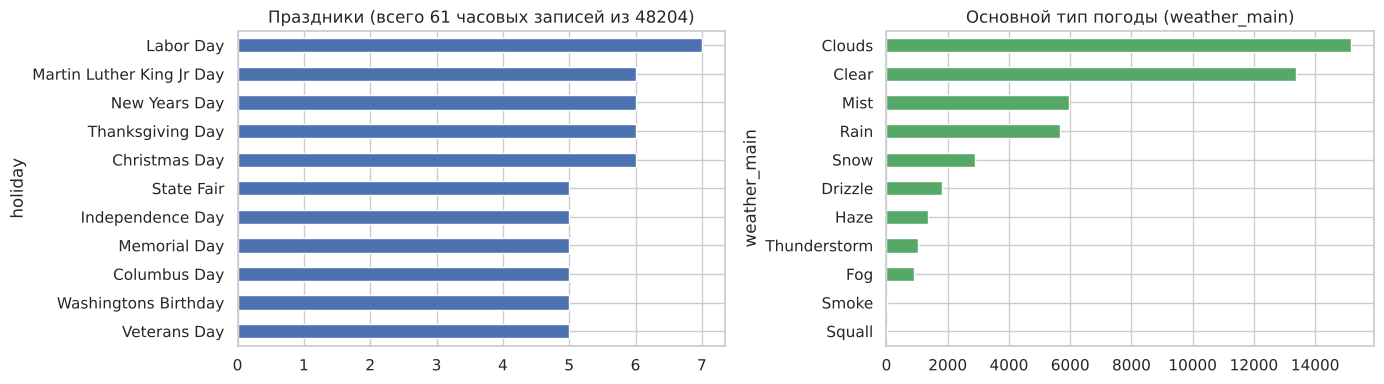

Число уникальных значений weather_description: 38


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_raw["holiday"].value_counts().drop("None").sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title(f"Праздники (всего {(df_raw['holiday']!='None').sum()} часовых записей из {len(df_raw)})")
df_raw["weather_main"].value_counts().sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Основной тип погоды (weather_main)")
plt.tight_layout(); plt.show()
print("Число уникальных значений weather_description:", df_raw["weather_description"].nunique())

**Пояснение к блоку кода.** Строим две столбчатые диаграммы: слева — количество часовых записей по каждому празднику (без значения `None`), справа — количество записей по основному типу погоды `weather_main`. Дополнительно печатаем число уникальных значений в `weather_description`. Цель — понять, насколько часто встречаются категории и нужно ли объединять редкие.

**Вывод по графикам.** Слева: праздничные записи единичны (5–7 часов на праздник), признак очень редкий. Справа: преобладают `Clouds` и `Clear`, а `Smoke` и `Squall` почти не встречаются — их придётся объединить. Подробнее — в абзаце ниже.

**Категориальные признаки.** Праздничных часов всего 61 из 48 204 (0.13%), то есть признак очень редкий; самые частые праздники встречаются 5–7 раз. Среди типов погоды преобладают `Clouds` (15 164) и `Clear` (13 391); редкие категории `Smoke` (20) и `Squall` (4) при кодировании будут объединены в `Other`. Столбец `weather_description` (38 значений) почти полностью дублирует `weather_main` по смыслу, поэтому в модель не берётся — это избежало бы десятков малозначимых бинарных столбцов.

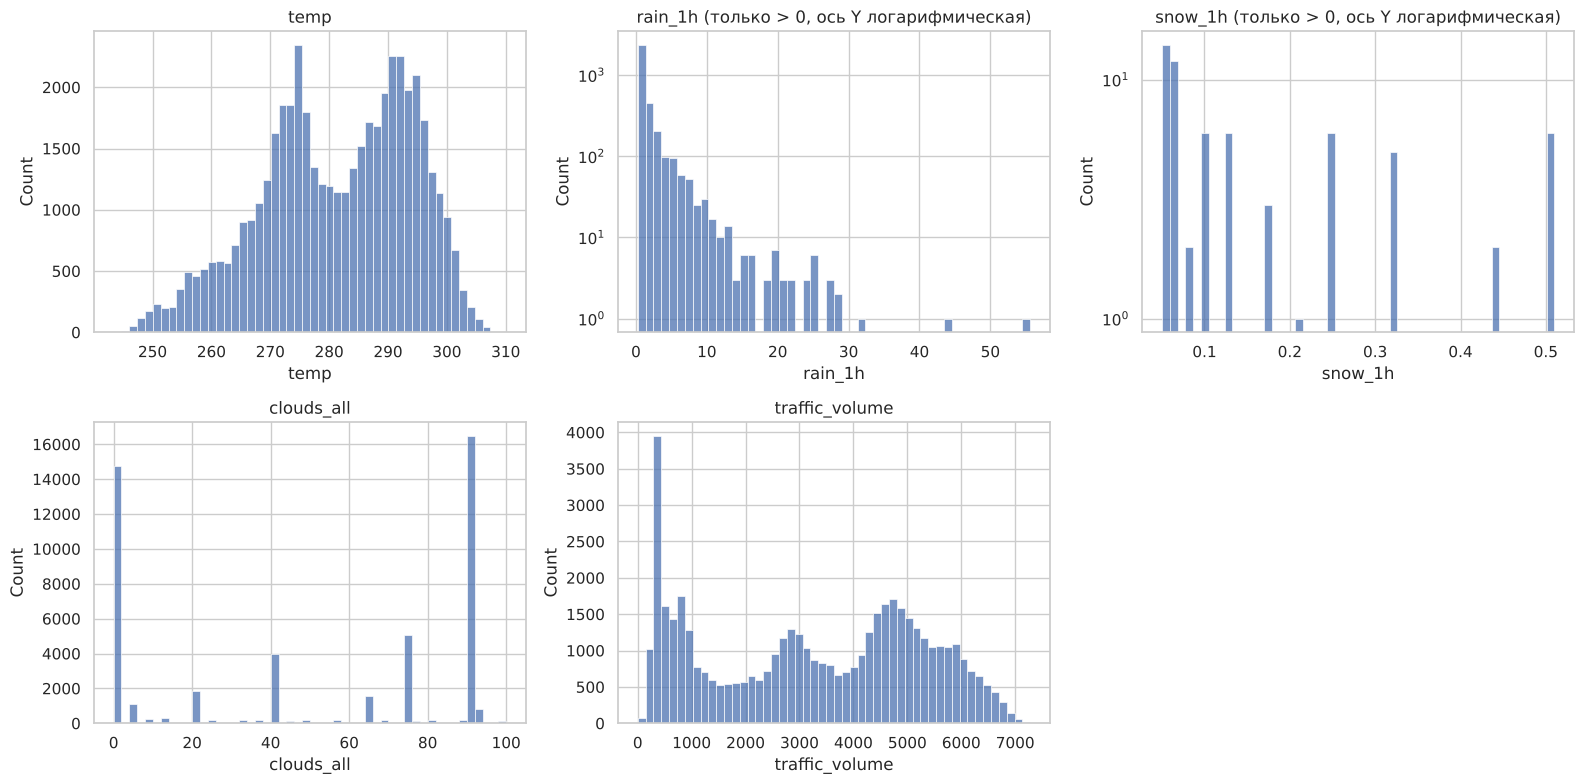

Доля часов без дождя: 92.8%;  без снега: 99.9%


In [6]:
num_cols = ["temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"]
# для читаемости графиков исключены явные аномалии (temp = 0 K и rain_1h ~ 9831 мм); дождь и снег - только ненулевые значения
plot_df = df_raw[(df_raw["temp"] > 0) & (df_raw["rain_1h"] < 1000)]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    data = plot_df.loc[plot_df[col] > 0, col] if col in ("rain_1h", "snow_1h") else plot_df[col]
    sns.histplot(data, bins=50, ax=ax, color="#4C72B0")
    ax.set_title(col + (" (только > 0, ось Y логарифмическая)" if col in ("rain_1h", "snow_1h") else ""))
    if col in ("rain_1h", "snow_1h"): ax.set_yscale("log")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()
print(f"Доля часов без дождя: {(df_raw['rain_1h'] == 0).mean():.1%};  без снега: {(df_raw['snow_1h'] == 0).mean():.1%}")

**Пояснение к блоку кода.** Для каждой числовой величины (температура, дождь, снег, облачность, трафик) строим гистограмму, чтобы увидеть форму распределения. Для читаемости из графиков убраны две аномалии (температура 0 К и дождь 9 831 мм), а для дождя и снега показаны только ненулевые значения на логарифмической оси — иначе из-за тысяч нулей гистограмма была бы одним столбиком. Под графиками выводится доля часов без дождя и без снега (92.8% и 99.9%).

**Вывод по графикам** — в следующем абзаце: целевая переменная бимодальна, температура близка к колоколу, осадки почти всегда нулевые, облачность принимает несколько «любимых» значений.

**Распределения признаков и целевой переменной.**

- **`traffic_volume`** — выраженно **бимодальное** распределение: пик около 300–500 автомобилей (ночные часы) и два широких «горба» около 3 000 и 4 800–5 000 (дневные часы и час пик). Нормальным оно не является — уже это говорит о том, что трафик определяется в первую очередь временем суток.
- **`temp`** (после исключения аномалии 0 К) — колоколообразное распределение с центром около 280–290 К и небольшим левым хвостом (зимние морозы).
- **`rain_1h`** и **`snow_1h`** — в 92.8% и 99.9% часов равны нулю; ненулевые значения показаны отдельно на логарифмической оси: подавляющее большинство дождей — малые (доли миллиметра), снег встречается в считанных часах.
- **`clouds_all`** — дискретное распределение с главными пиками при 0% и 90%, что характерно для метеонаблюдений (облачность округляется до стандартных значений).

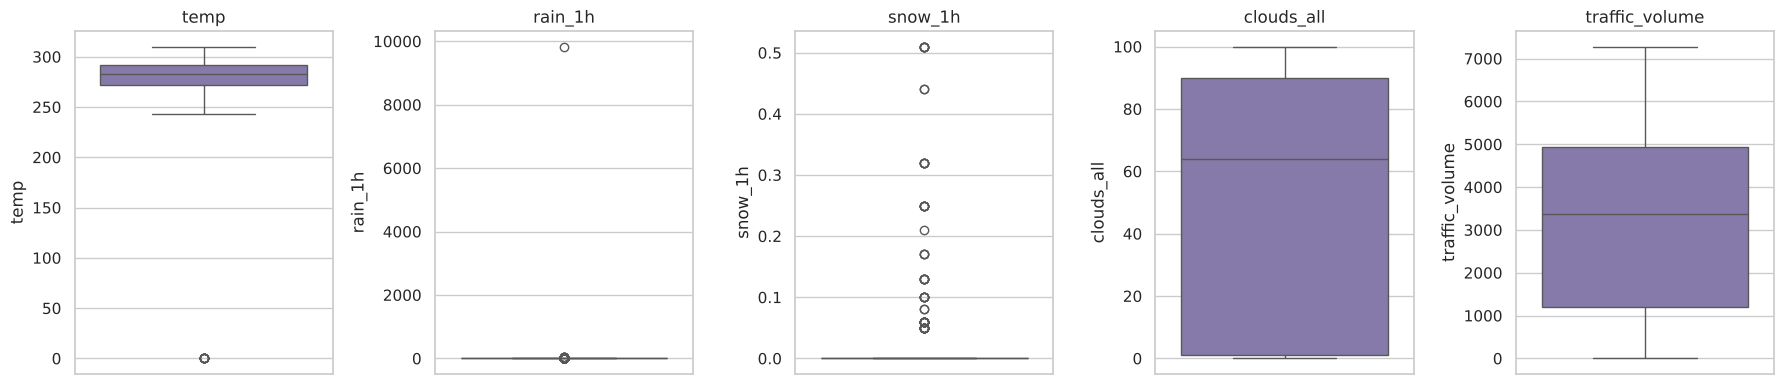

Аномалии:
  temp == 0 K            : 10 строк
  rain_1h > 1000 мм/ч    : 1 строк (max = 9831.3 )
  traffic_volume == 0    : 2 строк
  snow_1h > 0            : 63 строк;  rain_1h > 0: 3467


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_raw[col], ax=ax, color="#8172B2")
    ax.set_title(col)
plt.tight_layout(); plt.show()

print("Аномалии:")
print("  temp == 0 K            :", (df_raw["temp"] == 0).sum(), "строк")
print("  rain_1h > 1000 мм/ч    :", (df_raw["rain_1h"] > 1000).sum(), "строк (max =", df_raw["rain_1h"].max(), ")")
print("  traffic_volume == 0    :", (df_raw["traffic_volume"] == 0).sum(), "строк")
print("  snow_1h > 0            :", (df_raw["snow_1h"] > 0).sum(), "строк;  rain_1h > 0:", (df_raw["rain_1h"] > 0).sum())

**Пояснение к блоку кода.** Диаграммы размаха («ящики с усами») показывают медиану, межквартильный размах и выбросы по каждой числовой величине. Затем код считает, сколько в данных физически невозможных значений: температура 0 К, дождь больше 1 000 мм/ч, нулевой трафик, а также сколько реальных часов со снегом и дождём. Это нужно, чтобы отделить ошибки измерений (их удаляем) от редких, но настоящих событий (их оставляем).

**Вывод** — в абзаце ниже: аномалий мало (10 + 1 + 2 строки), и все они явно ошибочны.

**Выбросы и аномалии.** Диаграммы размаха подтверждают, что у `rain_1h` и `snow_1h` «ящик» вырожден в точку (почти все значения нулевые), а `temp` имеет выброс на 0 К. Подсчёт аномалий:

- **10 строк с `temp = 0` К** — ошибки датчика (реальная температура в Миннесоте не бывает −273 °C), удаляются;
- **1 строка с `rain_1h` = 9 831 мм/ч** — физически невозможно, удаляется;
- **2 строки с `traffic_volume = 0`** — вероятнее всего, сбой счётчика; кроме того, при нулевом факте MAPE не определена (деление на ноль), поэтому строки удаляются;
- 3 467 часов с дождём и 63 часа со снегом — это **реальные** редкие события, а не ошибки, их оставляем.

Остальные «выбросы» по правилу 1.5·IQR (например, сильные дожди) не удаляются: они отражают реальную погоду.

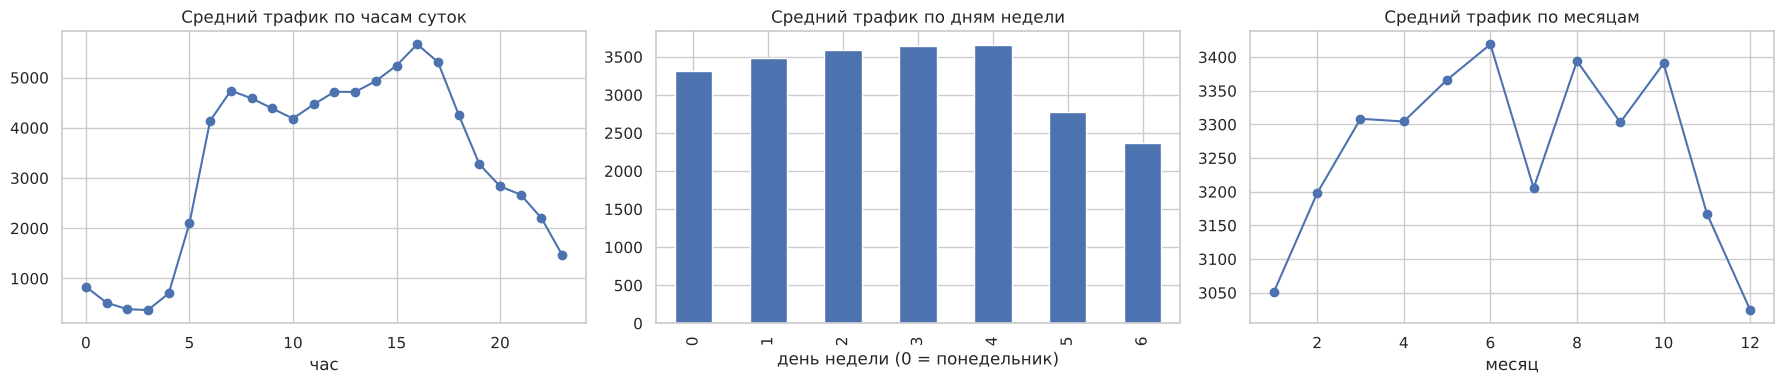

In [8]:
t = df_raw["date_time"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
df_raw.groupby(t.dt.hour)["traffic_volume"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Средний трафик по часам суток"); axes[0].set_xlabel("час")
df_raw.groupby(t.dt.dayofweek)["traffic_volume"].mean().plot.bar(ax=axes[1], color="#4C72B0")
axes[1].set_title("Средний трафик по дням недели"); axes[1].set_xlabel("день недели (0 = понедельник)")
df_raw.groupby(t.dt.month)["traffic_volume"].mean().plot(ax=axes[2], marker="o")
axes[2].set_title("Средний трафик по месяцам"); axes[2].set_xlabel("месяц")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Группируем данные по часу суток, дню недели и месяцу и строим средний трафик в каждой группе. Это разведочный анализ главного фактора: от него зависит, как закодировать время в признаках.

**Вывод по трём графикам.** Слева — резкий суточный профиль с двумя горбами; в центре — выходные тише будней; справа — сезонность слабая (колебания в пределах нескольких процентов). Следовательно, час суток нужно кодировать циклически и с двумя гармониками, а месяц — не обязательно детально. Подробно — в абзаце ниже.

**Зависимость трафика от времени.** На графиках видно главное:

- **Время суток — доминирующий фактор.** Ночью (1–3 ч) средний трафик ≈ 370–520 автомобилей в час, затем резкий рост в 5–7 ч (утренний час пик), плато днём и максимум около 16 ч (≈ 5 700); вечером спад. Кривая **не линейна и имеет два горба** — простая линейная зависимость от номера часа была бы неудачной, поэтому час кодируется циклически (см. ниже).
- **День недели.** В будни (пн–пт) средний трафик ≈ 3 300–3 650, в субботу ≈ 2 770, в воскресенье ≈ 2 360 — выходные заметно «тише».
- **Месяц.** Разброс по месяцам небольшой (≈ 3 020–3 420), сезонность слабая: летние и осенние месяцы чуть загруженнее, декабрь и январь — наименее.

## 2. Предобработка

In [ ]:
n0 = len(df_raw)
df = df_raw.copy()

# 1) полные дубликаты
df = df.drop_duplicates()
n1 = len(df)
# 2) несколько записей на один и тот же час (разные weather_description, одинаковый traffic_volume)
df = df.sort_values("date_time").drop_duplicates(subset="date_time", keep="first")
n2 = len(df)
# 3) физически невозможные значения: температура 0 K, дождь ~10 м/ч, нулевой трафик (MAPE не определён)
df = df[(df["temp"] > 0) & (df["rain_1h"] < 1000) & (df["traffic_volume"] > 0)]
n3 = len(df)
df = df.dropna().reset_index(drop=True)
n4 = len(df)

print(f"Исходно:                         {n0}")
print(f"после удаления полных дубликатов: {n1}  (-{n0-n1})")
print(f"после удаления дублей по часу:    {n2}  (-{n1-n2})")
print(f"после удаления аномалий:          {n3}  (-{n2-n3})")
print(f"после dropna:                     {n4}  (-{n3-n4})")

Исходно:                         48204
после удаления полных дубликатов: 48187  (-17)
после удаления дублей по часу:    40575  (-7612)
после удаления аномалий:          40562  (-13)
после dropna:                     40562  (-0)


**Пояснение к блоку кода.** Очистка выполняется последовательно, на каждом шаге печатается число оставшихся строк, чтобы видеть, что именно и сколько удалено: (1) полные дубликаты; (2) повторы по времени — оставляем первую запись на каждый час, потому что остальные дублируют один и тот же `traffic_volume` и дали бы утечку информации между обучающей и тестовой выборками; (3) физически невозможные значения (температура 0 К, дождь свыше 1 000 мм, нулевой трафик, при котором MAPE не определена); (4) `dropna` — пропусков нет, но шаг оставлен по заданию.

**Что видно из вывода:** 48 204 → 48 187 → 40 575 → 40 562 → 40 562 строки.

**Очистка данных.** Из 48 204 исходных строк осталось **40 562**:

- удалено 17 полных дубликатов;
- удалено 7 612 записей, повторяющих час (оставлена первая запись на каждый `date_time`) — объяснение в разделе «Пропуски и дубликаты»;
- удалено 13 строк с аномалиями (10 с `temp = 0` К, 1 с `rain_1h` = 9 831, 2 с нулевым трафиком);
- пропусков нет, `dropna` ничего не удалил (шаг оставлен согласно заданию, чтобы код работал и на «грязных» данных).

In [ ]:
t = df["date_time"]
hour, month = t.dt.hour, t.dt.month

X_all = pd.DataFrame({
    "temp_C":     df["temp"] - 273.15,
    "rain_1h":    df["rain_1h"],
    "snow_1h":    df["snow_1h"],
    "clouds_all": df["clouds_all"],
    # циклическое кодирование времени суток (период 24 ч): 1-я и 2-я гармоники
    "hour_sin":   np.sin(2*np.pi*hour/24),  "hour_cos":  np.cos(2*np.pi*hour/24),
    "hour2_sin":  np.sin(4*np.pi*hour/24),  "hour2_cos": np.cos(4*np.pi*hour/24),
    "month_sin":  np.sin(2*np.pi*month/12), "month_cos": np.cos(2*np.pi*month/12),
    "is_weekend": (t.dt.dayofweek >= 5).astype(int),
    "is_holiday": (df["holiday"] != "None").astype(int),
})

# One-Hot для weather_main (редкие Smoke и Squall объединены в Other; базовая категория Clear удалена)
weather = df["weather_main"].replace({"Smoke": "Other", "Squall": "Other"})
W = pd.get_dummies(weather, prefix="w").astype(int).drop(columns="w_Clear")

X = pd.concat([X_all, W], axis=1)
y = df["traffic_volume"]
FEATURES = list(X.columns)
print("Матрица признаков:", X.shape, "| целевая переменная:", y.name)
print("Признаки:", FEATURES)
X.head()

Матрица признаков: (40562, 21) | целевая переменная: traffic_volume
Признаки: ['temp_C', 'rain_1h', 'snow_1h', 'clouds_all', 'hour_sin', 'hour_cos', 'hour2_sin', 'hour2_cos', 'month_sin', 'month_cos', 'is_weekend', 'is_holiday', 'w_Clouds', 'w_Drizzle', 'w_Fog', 'w_Haze', 'w_Mist', 'w_Other', 'w_Rain', 'w_Snow', 'w_Thunderstorm']


,temp_C,rain_1h,snow_1h,clouds_all,hour_sin,hour_cos,hour2_sin,hour2_cos,month_sin,month_cos,...,is_holiday,w_Clouds,w_Drizzle,w_Fog,w_Haze,w_Mist,w_Other,w_Rain,w_Snow,w_Thunderstorm
0,15.1300,0.0000,0.0000,40,0.7071,-0.7071,-1.0000,-0.0000,-0.8660,0.5000,...,0,1,0,0,0,0,0,0,0,0
1,16.2100,0.0000,0.0000,75,0.5000,-0.8660,-0.8660,0.5000,-0.8660,0.5000,...,0,1,0,0,0,0,0,0,0,0
2,16.4300,0.0000,0.0000,90,0.2588,-0.9659,-0.5000,0.8660,-0.8660,0.5000,...,0,1,0,0,0,0,0,0,0,0
3,16.9800,0.0000,0.0000,90,0.0000,-1.0000,-0.0000,1.0000,-0.8660,0.5000,...,0,1,0,0,0,0,0,0,0,0
4,17.9900,0.0000,0.0000,75,-0.2588,-0.9659,0.5000,0.8660,-0.8660,0.5000,...,0,1,0,0,0,0,0,0,0,0


**Пояснение к блоку кода.** Здесь строится матрица признаков `X` и целевой вектор `y`. Температура переводится из кельвинов в градусы Цельсия. Час суток и месяц кодируются парами `sin/cos`, чтобы модель «знала», что 23:00 и 00:00 близки, а декабрь и январь соседние; для часа берутся две гармоники, чтобы уловить два пика суток. Из даты получаем признаки «выходной» и «праздник». Категориальный `weather_main` кодируется One-Hot (`get_dummies`); редкие `Smoke` и `Squall` объединены в `Other`, категория `Clear` удалена как базовая, чтобы индикаторы не были линейно зависимы (иначе VIF бесконечен, а матрица вырождена). Печатаем итоговую форму и первые строки.

**Что видно из вывода:** 40 562 строки и 21 признак; значения `sin/cos` лежат в [−1, 1], индикаторы погоды — 0/1.

**Формирование признаков.** Из исходных столбцов получено **21 признак**:

- **Числовые погодные:** `temp_C` (температура переведена из кельвинов в °C), `rain_1h`, `snow_1h`, `clouds_all`.
- **Циклическое кодирование времени.** Час суток и месяц — циклические величины (23:00 «рядом» с 00:00, декабрь «рядом» с январём), а обычное число 0–23 этого не отражает. Поэтому час закодирован парами `sin/cos` с периодом 24 ч, причём взяты две гармоники (`hour_*` и `hour2_*`): первая описывает один суточный цикл, вторая позволяет модели уловить два горба (утренний и вечерний час пик). Месяц закодирован парой `sin/cos` с периодом 12.
- **Бинарные:** `is_weekend` (суббота и воскресенье), `is_holiday` (в `holiday` стоит название праздника).
- **One-Hot кодирование `weather_main`:** 9 индикаторов (`Clouds, Drizzle, Fog, Haze, Mist, Rain, Snow, Thunderstorm, Other`); категория `Clear` удалена как базовая, чтобы не создавать «ловушку фиктивных переменных» (полную линейную зависимость индикаторов).

Календарный год в признаки не включён: он монотонно растёт и приводил бы к экстраполяции, а не к закономерности. Столбец `weather_description` не используется (см. выше).

**Разбиение и масштабирование** выполняются в следующих разделах: выборка делится на обучающую и тестовую **до** обучения любых преобразований, `StandardScaler` обучается только на обучающей части.

## 3. Корреляции и мультиколлинеарность

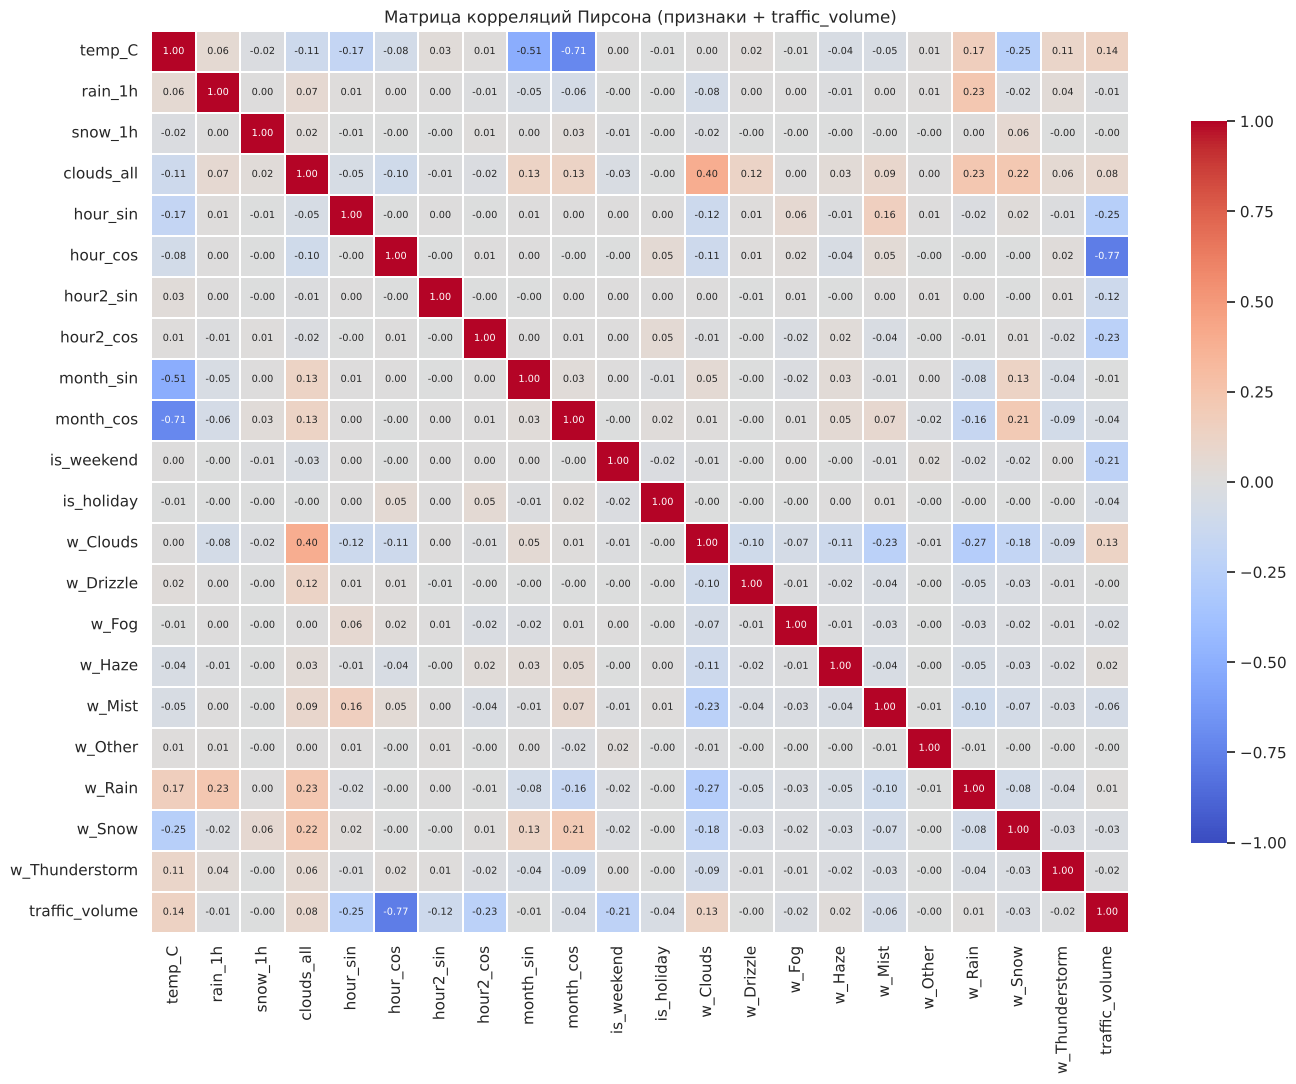

Корреляция признаков с traffic_volume:


,r
hour_cos,-0.7668
hour_sin,-0.2542
hour2_cos,-0.2304
is_weekend,-0.2122
temp_C,0.1393
w_Clouds,0.1265
hour2_sin,-0.1161
clouds_all,0.0781
w_Mist,-0.0649
month_cos,-0.0442


In [11]:
corr = pd.concat([X, y], axis=1).corr(method="pearson")

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=.3, cbar_kws={"shrink": .8})
plt.title("Матрица корреляций Пирсона (признаки + traffic_volume)")
plt.tight_layout(); plt.show()

print("Корреляция признаков с traffic_volume:")
corr["traffic_volume"].drop("traffic_volume").sort_values(key=abs, ascending=False).to_frame("r")

**Пояснение к блоку кода.** Считаем попарные корреляции Пирсона между всеми признаками и целевой переменной и выводим их тепловой картой (красный — положительная связь, синий — отрицательная). Ниже печатается таблица корреляций признаков с `traffic_volume`, отсортированная по модулю. Цель — увидеть, какие признаки связаны с целью и какие связаны между собой (кандидаты на мультиколлинеарность).

**Вывод по карте и таблице** приведён в абзаце ниже: самая сильная связь с целью — `hour_cos` (−0.77), погодные признаки слабы.

**Матрица корреляций (Пирсон).** Выбран коэффициент Пирсона, так как модель линейная и нас интересует именно линейная связь. На тепловой карте (красный — положительная связь, синий — отрицательная) видно:

**Связь признаков с целью `traffic_volume`:**

- **`hour_cos` (r = −0.77)** — самая сильная связь в наборе: она отражает, что трафик низкий в ночные часы (где cos часа ≈ +1, то есть вокруг полуночи) и высокий днём. Остальные компоненты времени суток: `hour_sin` (−0.25), `hour2_cos` (−0.23).
- **`is_weekend` (−0.21)** — в выходные трафик ниже.
- `temp_C` (+0.14), `w_Clouds` (+0.13), `clouds_all` (+0.08) — слабые связи; `rain_1h` (−0.01), `snow_1h` (−0.002), `is_holiday` (−0.04) почти не коррелируют с целью по отдельности. (Праздников всего 61 час, и их влияние теряется среди 40 тысяч наблюдений.)

**Связи между признаками (мультиколлинеарность):**

- единственная заметная пара — **`temp_C` и `month_cos` (r = −0.71)**, а также `temp_C` и `month_sin` (−0.51): это естественно — температура определяется сезоном;
- остальные пары слабее по модулю 0.5; в частности, `clouds_all` связана с индикатором `w_Clouds`, (r = 0.40), но не критично.

Получается, что погода и календарь почти независимы: погодные признаки не объясняют трафик, пока не учтено время суток.

In [12]:
# пары признаков с |r| >= 0.5
pairs = (corr.drop(index="traffic_volume", columns="traffic_volume")
             .where(np.triu(np.ones((len(FEATURES), len(FEATURES))), k=1).astype(bool))
             .stack().rename("r").to_frame())
pairs[pairs["r"].abs() >= 0.5].sort_values("r", key=abs, ascending=False)

r
temp_C month_cos -0.7132
       month_sin -0.5126

**Пояснение к блоку кода.** Из матрицы корреляций отбираются пары признаков с |r| ≥ 0.5 (верхний треугольник, чтобы не дублировать пары). Так находятся кандидаты на мультиколлинеарность без ручного просмотра карты 22×22.

**Что видно из вывода.** Таких пар всего две: `temp_C` — `month_cos` (r = −0.71) и `temp_C` — `month_sin` (r = −0.51). Это логично: температура определяется сезоном. Других сильных связей между признаками нет, значит, мультиколлинеарность будет слабой; точнее её покажет VIF.

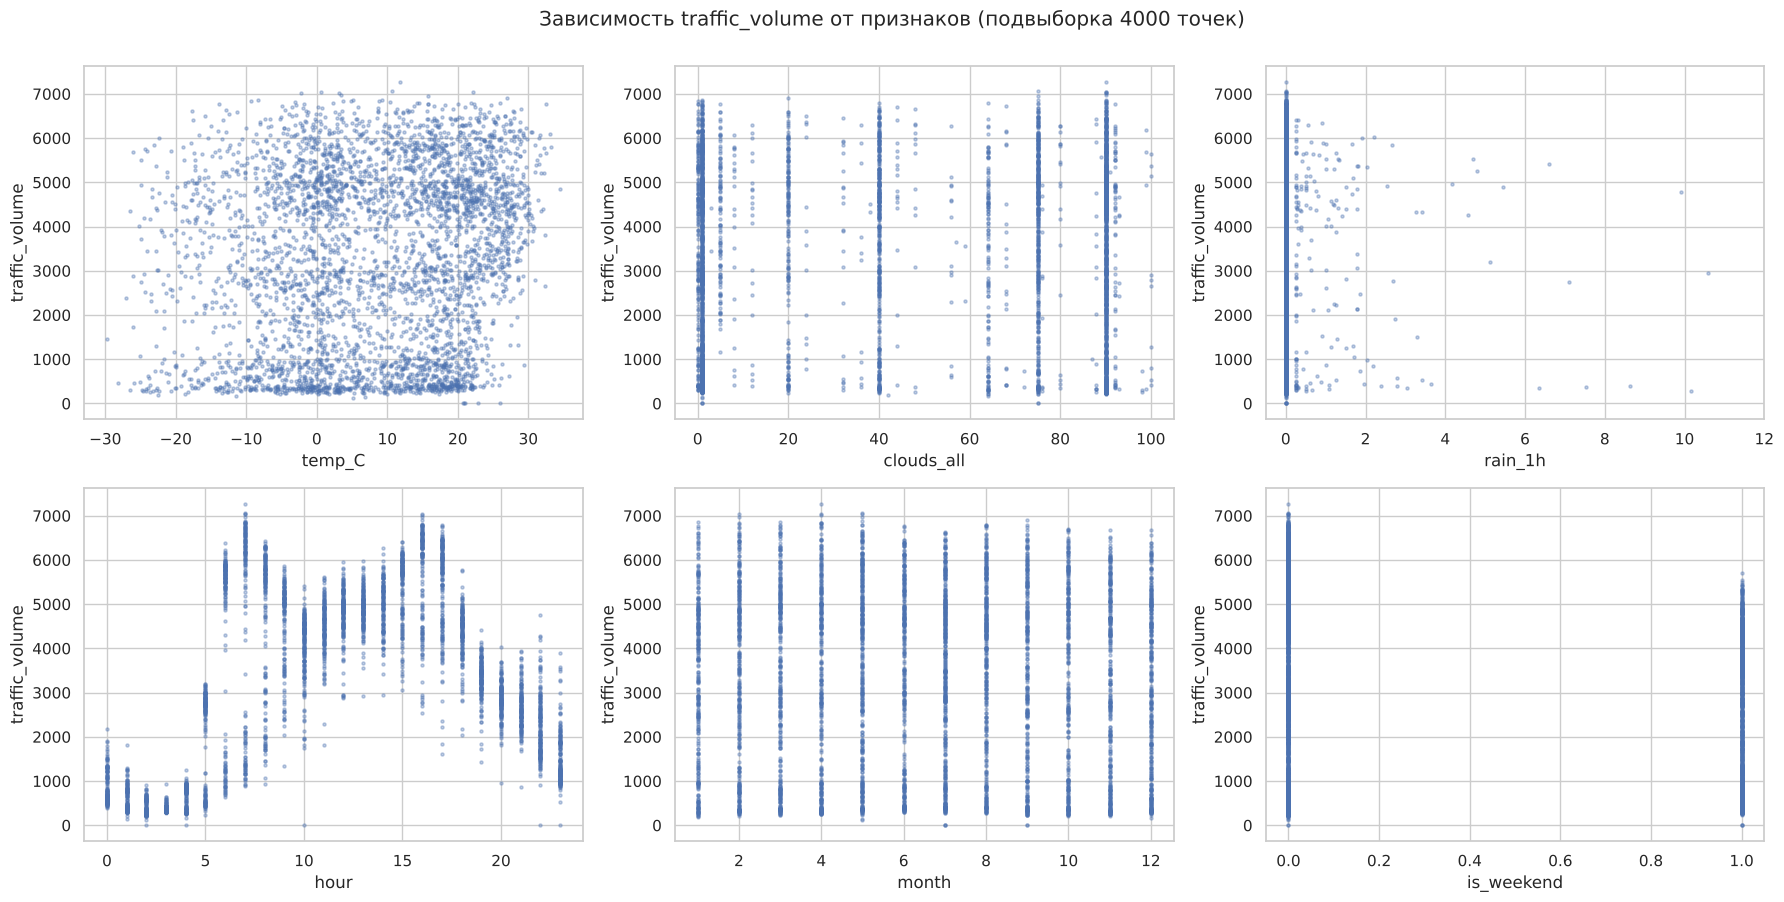

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
sample = df.sample(4000, random_state=RANDOM_STATE)
for ax, (col, xs) in zip(axes.ravel(), [("temp_C", X["temp_C"]), ("clouds_all", X["clouds_all"]),
                                       ("rain_1h", X["rain_1h"]), ("hour", hour),
                                       ("month", month), ("is_weekend", X["is_weekend"])]):
    ax.scatter(xs.loc[sample.index], sample["traffic_volume"], s=5, alpha=.35, color="#4C72B0")
    ax.set_xlabel(col); ax.set_ylabel("traffic_volume")
    if col == "rain_1h": ax.set_xlim(-0.5, 12)
plt.suptitle("Зависимость traffic_volume от признаков (подвыборка 4000 точек)", y=1.0)
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Для наглядной проверки зависимости цели от признаков строим диаграммы рассеяния `traffic_volume` против температуры, облачности, осадков, часа, месяца и признака выходного. Для читаемости взята случайная подвыборка из 4 000 точек (на 40 тысячах точек график превращается в сплошное пятно); на ось осадков ограничена область до 12 мм.

**Вывод по графикам** — в абзаце ниже: сильная нелинейная зависимость только от часа суток, остальные признаки образуют облака без выраженного тренда.

**Зависимость `traffic_volume` от признаков (визуально).**

- **Температура и облачность** — облако точек почти без тренда: при любой температуре и облачности встречаются как пустые ночные часы, так и час пик. Это соответствует низким корреляциям (0.14 и 0.08).
- **Осадки (`rain_1h`)** — большая часть точек сосредоточена на нуле; при ненулевых осадках трафик распределён так же широко, как и без них.
- **Час суток** — чёткая, сильная, но **нелинейная** зависимость: ночной минимум, резкий рост в 5–7 ч и спад к вечеру. Именно она определяет качество всех следующих моделей.
- **Месяц** — графики практически одинаковы, зависимости почти нет.
- **Выходной** — у выходных верхняя граница трафика заметно ниже (≈ 5 700 против ≈ 7 300 в будни).

In [14]:
def compute_vif(X):
    """VIF_j = 1 / (1 - R^2_j), где R^2_j - от регрессии признака j на остальные признаки."""
    out = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        out[col] = np.inf if r2 >= 1 else 1.0 / (1.0 - r2)
    return pd.Series(out, name="VIF")

vif_orig = compute_vif(X).sort_values(ascending=False)
vif_orig.to_frame()

,VIF
temp_C,4.8417
month_cos,3.4500
w_Clouds,2.9877
clouds_all,2.7441
month_sin,2.2101
w_Rain,2.1144
w_Snow,1.6789
w_Mist,1.5635
w_Drizzle,1.2249
hour_sin,1.1805


**Пояснение к блоку кода.** Функция `compute_vif` для каждого признака строит линейную регрессию на все остальные, берёт её R² и считает VIF = 1/(1−R²) — во сколько раз дисперсия оценки коэффициента раздувается из-за коллинеарности. Целевая переменная в расчёт не входит. Результат сортируется по убыванию. Чем больше VIF, тем сильнее признак линейно выражается через остальные (порог осторожности — 5, серьёзной проблемы — 10).

**Вывод по таблице** — в абзаце ниже: максимум 4.84 у `temp_C`.

**VIF.** Для каждого признака VIF = 1/(1−R²), где R² — коэффициент детерминации регрессии этого признака на все остальные (функция написана вручную через `LinearRegression`, чтобы не зависеть от `statsmodels`). Целевая переменная в расчёт не входит. Общепринятые пороги: VIF > 5 — осторожность, VIF > 10 — серьёзная мультиколлинеарность.

Результат: наибольший VIF у `temp_C` — **4.84**, затем `month_cos` (3.45), `w_Clouds` (2.99) и `clouds_all` (2.74); у остальных 17 признаков VIF от 1.0 до 2.2. Значит, мультиколлинеарность **слабая-умеренная**: ни один признак не превышает порог 5, а `temp_C` подходит к нему вплотную (температура линейно выражается через сезон — `month_cos` и `month_sin`). Коэффициенты линейной регрессии при `temp_C` и `month_*` могут быть чуть менее устойчивы, но на качество прогноза это почти не повлияет.

Для сравнения: если бы мы не удалили базовую категорию `Clear`, индикаторы погоды были бы полностью линейно зависимы (VIF → ∞).

## 4. Разбиение выборки, метрики, модели на исходных признаках

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Обучающая выборка:", X_train.shape, "| тестовая:", X_test.shape)
print(f"Среднее traffic_volume: train = {y_train.mean():.1f}, test = {y_test.mean():.1f}")

Обучающая выборка: (32449, 21) | тестовая: (8113, 21)
Среднее traffic_volume: train = 3284.7, test = 3317.3


**Пояснение к блоку кода.** Разбиваем выборку функцией `train_test_split` в пропорции 80/20 с фиксированным `random_state`. Тестовая выборка откладывается и не используется ни при подборе параметров, ни при обучении стандартизатора или PCA — только для итоговой оценки. Дополнительно сравниваем средний трафик в двух частях, чтобы убедиться, что они сопоставимы.

**Вывод** — в абзаце ниже: 32 449 / 8 113 наблюдений, средние трафика 3 285 и 3 317.

**Разбиение 80/20.** Получено 32 449 обучающих и 8 113 тестовых наблюдений. `random_state=42` фиксирует перемешивание. Средний трафик в обучающей (3 285) и тестовой (3 317) выборках близок, то есть выборки сопоставимы.

Случайное разбиение допустимо по условию задания (`train_test_split`), но важна оговорка: данные — временной ряд, и соседние часы похожи друг на друга, поэтому случайный тест несколько «знает» окрестности обучающих точек. Для проверки в конце работы дополнительно выполнено хронологическое разбиение (раздел 7).

In [ ]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mape(y_true, y_pred):
    return mean_absolute_percentage_error(y_true, y_pred) * 100

def evaluate(model, Xtr, ytr, Xte, yte):
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    return {"RMSE train": rmse(ytr, p_tr), "RMSE test": rmse(yte, p_te),
            "R2 train": r2_score(ytr, p_tr), "R2 test": r2_score(yte, p_te),
            "MAPE test, %": mape(yte, p_te)}

**Пояснение к блоку кода.** Определены три функции метрик и общая функция `evaluate`: `rmse` — корень из среднеквадратичной ошибки, `mape` — средняя абсолютная процентная ошибка в процентах (обёртка над функцией scikit-learn), `evaluate` — считает RMSE и R² на обучающей и тестовой выборках и MAPE на тесте. Сравнение метрик на train и test позволяет отличить переобучение (train заметно лучше test) от недообучения (обе ошибки велики). Вывода у блока нет — он только определяет функции для следующих ячеек.

**Метрики.**

- **RMSE** = √MSE — корень из среднеквадратичной ошибки, в тех же единицах, что и цель (автомобили в час); сильнее штрафует крупные ошибки.
- **R²** — доля дисперсии цели, объяснённая моделью (1 — идеально, 0 — не лучше среднего).
- **MAPE** — средняя абсолютная процентная ошибка, в процентах (доля умножена на 100).

**Оговорка про MAPE.** Метрика делит ошибку на фактическое значение, поэтому при очень малом фактическом трафике (в тесте минимальное значение — 1 автомобиль в час) даже небольшая абсолютная ошибка даёт огромную процентную. Ниже будет показано, что общее значение MAPE определяется горсткой таких наблюдений; поэтому основными метриками считаются RMSE и R², а MAPE интерпретируется осторожно.

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas_lasso = np.logspace(-3, 2, 30)
alphas_ridge = np.logspace(-3, 3, 30)

def make_models(prefix_steps=()):
    """Три модели; prefix_steps - шаги перед моделью (StandardScaler, при необходимости PCA)."""
    lin = Pipeline([*prefix_steps, ("model", LinearRegression())])
    lasso = GridSearchCV(Pipeline([*prefix_steps, ("model", Lasso(max_iter=20000))]),
                         {"model__alpha": alphas_lasso}, cv=cv, scoring="neg_root_mean_squared_error")
    ridge = GridSearchCV(Pipeline([*prefix_steps, ("model", Ridge())]),
                         {"model__alpha": alphas_ridge}, cv=cv, scoring="neg_root_mean_squared_error")
    return {"Линейная": lin, "Лассо": lasso, "Гребневая": ridge}

def fit_and_score(models, Xtr, ytr, Xte, yte, label):
    rows, fitted = [], {}
    for name, m in models.items():
        m.fit(Xtr, ytr)
        est = m.best_estimator_ if isinstance(m, GridSearchCV) else m
        alpha = m.best_params_["model__alpha"] if isinstance(m, GridSearchCV) else np.nan
        cv_rmse = (-m.best_score_ if isinstance(m, GridSearchCV)
                   else -cross_val_score(m, Xtr, ytr, cv=cv, scoring="neg_root_mean_squared_error").mean())
        rows.append({"Признаки": label, "Модель": name, "alpha": alpha, "CV RMSE": cv_rmse,
                     **evaluate(est, Xtr, ytr, Xte, yte)})
        fitted[name] = est
    return pd.DataFrame(rows), fitted

models_orig = make_models([("scaler", StandardScaler())])
res_orig, fitted_orig = fit_and_score(models_orig, X_train, y_train, X_test, y_test, "Исходные")
res_orig

,Признаки,Модель,alpha,CV RMSE,RMSE train,RMSE test,R2 train,R2 test,"MAPE test, %"
0,Исходные,Линейная,NaN,959.8086,959.0546,957.8073,0.7667,0.7659,138.6339
1,Исходные,Лассо,1.2690,959.7747,959.0814,957.7935,0.7667,0.7660,138.9022
2,Исходные,Гребневая,13.7382,959.8079,959.0548,957.8043,0.7667,0.7659,138.6858


**Пояснение к блоку кода.** Создаём три модели — линейную, лассо и гребневую — и обучаем каждую внутри `Pipeline` (`StandardScaler → модель`), чтобы стандартизация обучалась только на обучающей части каждого блока кросс-валидации и не «подглядывала» в тест. Для лассо и гребневой регрессии параметр регуляризации `alpha` подбирается `GridSearchCV` по сетке из 30 значений на логарифмической шкале с 5-кратной кросс-валидацией (`KFold`, метрика — RMSE). Функция `fit_and_score` собирает в таблицу выбранный `alpha`, CV-RMSE, RMSE и R² на train и test и MAPE на test. Для линейной регрессии CV-RMSE считается отдельно через `cross_val_score`.

**Что видно из таблицы** — ниже, в описании результатов: три модели дают практически одинаковые метрики.

**Модели на исходных признаках.** Все преобразования стоят внутри `Pipeline` (`StandardScaler → модель`), поэтому в каждом из 5 блоков кросс-валидации (`KFold` с перемешиванием, метрика — отрицательный RMSE) стандартизатор заново обучается только на обучающей части блока. Параметр `alpha` для лассо и гребневой регрессии подбирается `GridSearchCV` по 30 значениям на логарифмической сетке (лассо: 0.001–100; гребневая: 0.001–1000), `max_iter=20000` для лассо задан явно.

Результаты на тесте:

| Модель | alpha | CV RMSE | RMSE test | R² test | MAPE test |
|---|---|---|---|---|---|
| Линейная | — | 959.8 | 957.8 | 0.766 | 138.6% |
| Лассо | 1.27 | 959.8 | 957.8 | 0.766 | 138.9% |
| Гребневая | 13.7 | 959.8 | 957.8 | 0.766 | 138.7% |

**Три модели практически неразличимы.** Это ожидаемо: у нас 32 тысячи наблюдений и всего 21 признак, мультиколлинеарность слабая (VIF < 5), поэтому регуляризации нечего «лечить» — оптимальное `alpha` мало́ (для гребневой 13.7 при 32 449 наблюдениях — слабый штраф), и модели почти совпадают с обычными наименьшими квадратами. Кроме того, ошибки на обучающей и тестовой выборках почти равны (RMSE 959.1 и 957.8; R² 0.767 и 0.766) — **переобучения нет**, наоборот, модель **недообучена**: её ограничение не в количестве данных, а в линейной форме зависимости (подробно — ниже).

In [18]:
coefs = pd.DataFrame({name: est.named_steps["model"].coef_ for name, est in fitted_orig.items()}, index=FEATURES)
coefs["|Линейная|"] = coefs["Линейная"].abs()
coefs.sort_values("|Линейная|", ascending=False).drop(columns="|Линейная|")

,Линейная,Лассо,Гребневая
hour_cos,"-1,517.0717","-1,515.8333","-1,516.3911"
hour_sin,-494.8902,-493.8141,-494.6209
hour2_cos,-451.7071,-450.5196,-451.5237
is_weekend,-427.4172,-426.1707,-427.2317
hour2_sin,-235.7099,-234.2659,-235.6162
temp_C,74.2850,71.5352,74.5116
month_sin,40.3233,36.9828,40.3972
clouds_all,-38.7436,-31.3956,-38.6342
w_Snow,-28.1984,-30.8551,-28.2003
month_cos,-23.8436,-25.3574,-23.6918


**Пояснение к блоку кода.** Из обученных конвейеров берутся коэффициенты моделей (при стандартизованных признаках) и собираются в одну таблицу, отсортированную по модулю коэффициента линейной модели. Стандартизация делает коэффициенты сопоставимыми по величине: чем больше модуль, тем сильнее признак влияет на прогноз. Сравнение трёх столбцов показывает, как лассо и гребневая регрессия изменили коэффициенты.

**Коэффициенты моделей** (при стандартизованных признаках, то есть на изменение признака на одно стандартное отклонение; их можно сравнивать по величине):

- **`hour_cos` (−1 517)** — главный фактор: колоссальный вклад по сравнению со всеми остальными; за ним `hour_sin` (−495), `hour2_cos` (−452) и `is_weekend` (−427, то есть выходные снижают трафик примерно на 430 автомобилей в час при прочих равных).
- `temp_C` (+74), `month_sin` (+40), `clouds_all` (−39) — малые вклады, `rain_1h` (−22) и `snow_1h` (−4) — практически ничтожные.
- Лассо обнулило только `w_Fog` (и сильно уменьшило `w_Rain`, `w_Mist`, `w_Clouds`) — отбор признаков минимален, потому что штраф слаб.

Вывод: **погода объясняет трафик очень слабо; модель почти целиком строится на времени суток и выходных.**

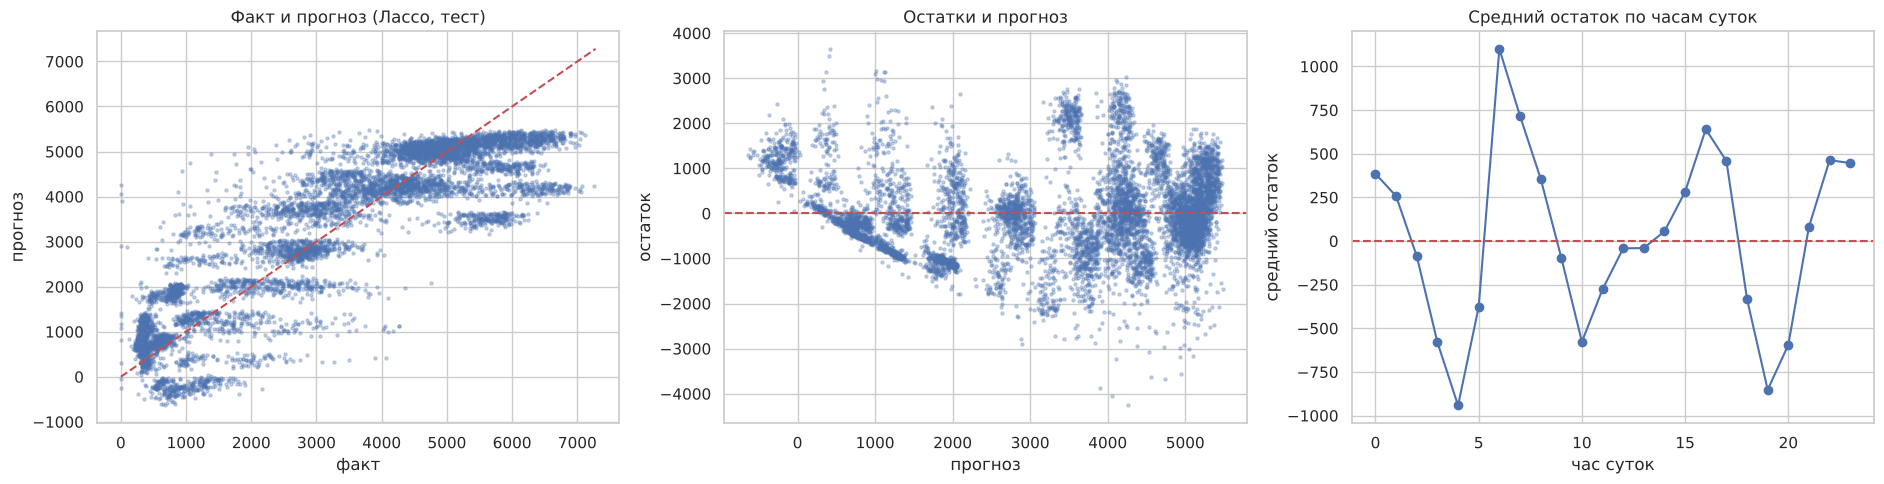

In [19]:
best_orig = res_orig.sort_values("CV RMSE").iloc[0]["Модель"]
pred = fitted_orig[best_orig].predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
axes[0].scatter(y_test, pred, s=5, alpha=.3, color="#4C72B0")
lims = [0, y.max()]; axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("факт"); axes[0].set_ylabel("прогноз")
axes[0].set_title(f"Факт и прогноз ({best_orig}, тест)")
axes[1].scatter(pred, resid, s=5, alpha=.3, color="#4C72B0"); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("прогноз"); axes[1].set_ylabel("остаток"); axes[1].set_title("Остатки и прогноз")
hrs = df.loc[X_test.index, "date_time"].dt.hour
resid.groupby(hrs).agg(["mean"]).plot(ax=axes[2], marker="o", legend=False)
axes[2].axhline(0, color="r", ls="--"); axes[2].set_xlabel("час суток"); axes[2].set_ylabel("средний остаток")
axes[2].set_title("Средний остаток по часам суток")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Берём модель, лучшую по CV-RMSE, строим прогноз на тесте и три графика: (1) факт против прогноза, красная линия — идеальный прогноз; (2) остатки (факт − прогноз) против прогноза — по нему проверяется предпосылка линейной регрессии о случайности остатков; (3) средний остаток по часам суток — показывает, в какие часы модель систематически ошибается.

**Вывод по графикам** — в абзаце ниже: «полосы» на первом графике, структура в остатках и волна на третьем — признаки нелинейной зависимости от времени суток.

**Прогноз и остатки** лучшей по кросс-валидации модели (лассо; различия между моделями ничтожны).

- **Левый график (факт и прогноз).** Красная пунктирная линия — идеальный прогноз. Точки образуют **горизонтальные «полосы»**: прогноз для всех наблюдений одного и того же часа почти одинаков (модель знает час суток, но не знает, какой именно сегодня день), а факт при этом сильно варьируется. Для малых значений трафика (факт < 1 000) модель иногда даёт **отрицательные прогнозы** (до ≈ −400), что физически невозможно — типичный недостаток линейной модели без ограничений.
- **Средний график (остатки и прогноз).** Остатки образуют заметные структурные «пятна» и «диагональные цепочки», а не однородное облако вокруг нуля: это признак **нарушения предпосылки линейной регрессии** (остатки должны быть случайными). Модель систематически ошибается в зависимости от времени суток.
- **Правый график (средний остаток по часам).** Отчётливая волна: в 6–7 ч модель **занижает** прогноз в среднем на 700–1 100 автомобилей (резкий утренний пик, который гладкие `sin/cos` не воспроизводят), в 3–5 ч и в 18–20 ч — **завышает** на 300–950. Суточный профиль трафика слишком «угловатый» для двух гармоник.

**Причина погрешности:** линейная модель не может точно описать нелинейный суточный профиль и различия профилей будней и выходных. Это ошибка модели (смещение), а не недостаток данных.

In [20]:
seg = pd.DataFrame({"hour": hrs, "y": y_test, "pred": pred})
seg["APE, %"] = (seg["y"] - seg["pred"]).abs() / seg["y"] * 100
seg["Период"] = np.where(seg["hour"] <= 5, "ночь (0-5 ч)", "день (6-23 ч)")
seg["|ошибка|"] = (seg["y"] - seg["pred"]).abs()
seg_tab = seg.groupby("Период").agg(наблюдений=("y", "size"), средний_трафик=("y", "mean"),
                                    MAE=("|ошибка|", "mean"), MAPE=("APE, %", "mean"))
display(seg_tab)
print(f"Средняя APE (это и есть MAPE): {seg['APE, %'].mean():.1f}%;  медианная APE: {seg['APE, %'].median():.1f}%;  максимальная APE: {seg['APE, %'].max():,.0f}%")
print(f"Минимальный трафик в тесте: {y_test.min()};  наблюдений с трафиком < 100: {(y_test < 100).sum()} из {len(y_test)}")
print("\nMAPE при исключении наблюдений с малым фактическим трафиком:")
for thr in [0, 50, 100, 300, 500, 1000]:
    sub = seg[seg["y"] >= thr]
    print(f"  трафик >= {thr:<5}: n = {len(sub):5d},  MAPE = {sub['APE, %'].mean():7.1f}%")

,наблюдений,средний_трафик,MAE,MAPE
Период,,,,
день (6-23 ч),6138,"4,119.3897",762.9262,136.5499
ночь (0-5 ч),1975,824.7276,638.3112,146.2127


Средняя APE (это и есть MAPE): 138.9%;  медианная APE: 19.0%;  максимальная APE: 213,051%
Минимальный трафик в тесте: 1;  наблюдений с трафиком < 100: 13 из 8113

MAPE при исключении наблюдений с малым фактическим трафиком:
  трафик >= 0    : n =  8113,  MAPE =   138.9%
  трафик >= 50   : n =  8101,  MAPE =    47.0%
  трафик >= 100  : n =  8100,  MAPE =    46.6%
  трафик >= 300  : n =  7922,  MAPE =    43.0%
  трафик >= 500  : n =  7216,  MAPE =    33.0%
  трафик >= 1000 : n =  6369,  MAPE =    23.3%


**Пояснение к блоку кода.** Считаем процентную ошибку каждого наблюдения теста (APE), сравниваем «ночь» и «день», выводим среднюю, медианную и максимальную APE, число наблюдений с очень малым трафиком, а затем пересчитываем MAPE, постепенно исключая наблюдения с малым фактическим трафиком (порог 0, 50, 100, 300, 500, 1 000). Цель — понять, почему MAPE на порядок хуже, чем подсказывает R².

**Что видно из вывода:** средняя APE 138.9% при медианной 19%, максимальная 213 051% (факт = 1 автомобиль), а при пороге 100 MAPE равна 46.6%. Объяснение — в абзаце ниже.

**Почему MAPE = 139%, если R² = 0.77?** Диагностика показывает, что среднее значение MAPE определяется редкими наблюдениями с малым фактическим трафиком:

- **медианная** процентная ошибка всего **19%**, а **средняя (MAPE) — 139%**;
- максимальная процентная ошибка — **213 051%**: это наблюдение с фактическим трафиком в **1 автомобиль** в час, где даже ошибка в 2 000 автомобилей даёт гигантский процент;
- всего **13 наблюдений из 8 113** имеют трафик менее 100; при их исключении MAPE падает до **46.6%**, при трафике ≥ 500 — до 33%, ≥ 1000 — до 23%.

Разделение «день / ночь» среднее MAPE почти не меняет (136.5% и 146.2%), то есть дело не просто в ночных часах, а именно в единичных сверхмалых значениях. Вывод: **MAPE на этих данных нужно интерпретировать с осторожностью**; для сравнения моделей надёжнее RMSE и R², а в сравнении ниже MAPE показан тоже, как требует задание.

## 5. Стандартизация и PCA

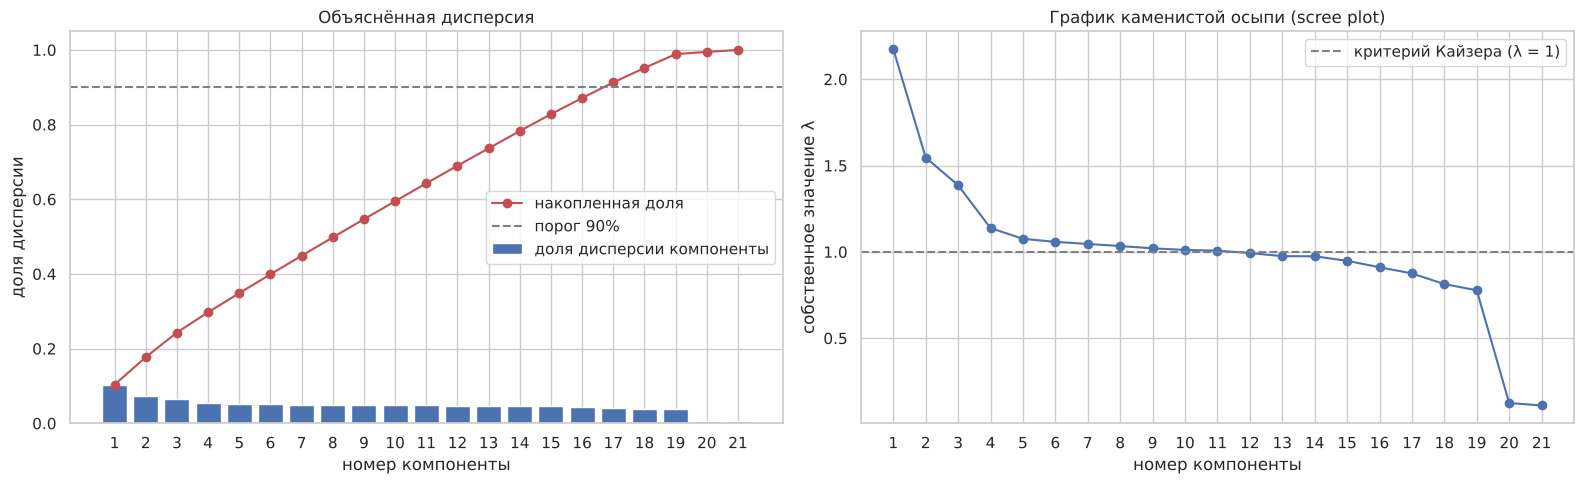

               PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9   PC10   PC11   PC12   PC13   PC14   PC15   PC16   PC17   PC18   PC19   PC20   PC21
λ           2.1748 1.5467 1.3860 1.1379 1.0756 1.0581 1.0459 1.0338 1.0206 1.0112 1.0072 0.9933 0.9753 0.9743 0.9483 0.9109 0.8753 0.8133 0.7776 0.1245 0.1101
доля        0.1036 0.0737 0.0660 0.0542 0.0512 0.0504 0.0498 0.0492 0.0486 0.0482 0.0480 0.0473 0.0464 0.0464 0.0452 0.0434 0.0417 0.0387 0.0370 0.0059 0.0052
накопленная 0.1036 0.1772 0.2432 0.2974 0.3486 0.3990 0.4488 0.4980 0.5466 0.5948 0.6427 0.6900 0.7365 0.7829 0.8280 0.8714 0.9131 0.9518 0.9888 0.9948 1.0000


In [ ]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
pc_names = [f"PC{i+1}" for i in range(len(evr))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(range(1, len(evr)+1), evr, color="#4C72B0", label="доля дисперсии компоненты")
axes[0].plot(range(1, len(evr)+1), cum, "o-", color="#C44E52", label="накопленная доля")
axes[0].axhline(0.90, color="gray", ls="--", label="порог 90%")
axes[0].set_xlabel("номер компоненты"); axes[0].set_ylabel("доля дисперсии"); axes[0].set_xticks(range(1, len(evr)+1))
axes[0].set_title("Объяснённая дисперсия"); axes[0].legend()
axes[1].plot(range(1, len(evr)+1), pca_full.explained_variance_, "o-", color="#4C72B0")
axes[1].axhline(1, color="gray", ls="--", label="критерий Кайзера (λ = 1)")
axes[1].set_xlabel("номер компоненты"); axes[1].set_ylabel("собственное значение λ"); axes[1].set_xticks(range(1, len(evr)+1))
axes[1].set_title("График каменистой осыпи (scree plot)"); axes[1].legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({"λ": pca_full.explained_variance_, "доля": evr, "накопленная": cum}, index=pc_names).round(4).T.to_string())

**Пояснение к блоку кода.** Стандартизатор обучается только на обучающей выборке и применяется к обучающей и тестовой. Затем обучается PCA со всеми 21 компонентой на стандартизованных обучающих данных (стандартизация перед PCA обязательна: иначе компоненты определялись бы признаками с наибольшим масштабом). Строятся два графика: слева — доля дисперсии каждой компоненты и накопленная доля с порогом 90%; справа — **график каменистой осыпи** (собственные значения λ) с линией λ = 1 (критерий Кайзера). Ниже печатается таблица λ, долей и накопленных долей.

**Вывод по графикам и таблице** — в абзаце ниже.

**Стандартизация и PCA.** Стандартизатор обучается (`fit`) только на обучающей выборке, затем применяется (`transform`) к обучающей и тестовой выборкам — информация из теста не попадает в преобразование. PCA обучается на стандартизованных обучающих данных, при этом сохранены все 21 компонента, чтобы построить график каменистой осыпи.

**Как читать графики.** Слева — доля дисперсии каждой компоненты (столбцы) и накопленная доля (красная линия) с порогом 90%. Справа — **график каменистой осыпи (scree plot)**: собственные значения λ компонент в порядке убывания; серая линия λ = 1 — критерий Кайзера (оставлять компоненты, объясняющие дисперсию больше одного исходного стандартизованного признака).

Что видно:

- Первая компонента объясняет лишь **10.4%** дисперсии, вторая — 7.4%, третья — 6.6%. Дисперсия распределена **почти равномерно** — это ключевая особенность данных: признаки в основном **независимы** (корреляции слабые, VIF < 5), поэтому PCA почти нечего «сжимать».
- Накопленные доли: 17 компонент — 91.3% (порог 90% достигается при **k = 17**), 19 компонент — 98.9%.
- По критерию Кайзера (λ > 1) получается **k = 11** (всего 64.3% дисперсии) — для данных с почти равномерным спектром этот критерий даёт слишком мало компонент.
- На графике каменистой осыпи есть единственный выраженный **излом между 19-й и 20-й компонентами**: λ падает с 0.78 до 0.12. Две последние компоненты (PC20 и PC21) — направления почти точной линейной зависимости признаков: PC21 образована в основном `temp_C`, `month_cos` и `month_sin` (температура ↔ сезон), PC20 — `w_Clouds`, `clouds_all`, `w_Rain` и `w_Snow` (облачность ↔ тип погоды); именно они отвечают за остаточную мультиколлинеарность. По «правилу излома» следует оставить **19 компонент**.

По порогу 90%: k = 17 (накопленная доля 91.31%)
По критерию Кайзера (λ>1): k = 11 (накопленная доля 64.27%)
Форма train: (32449, 21) -> (32449, 17) | test: (8113, 21) -> (8113, 17)


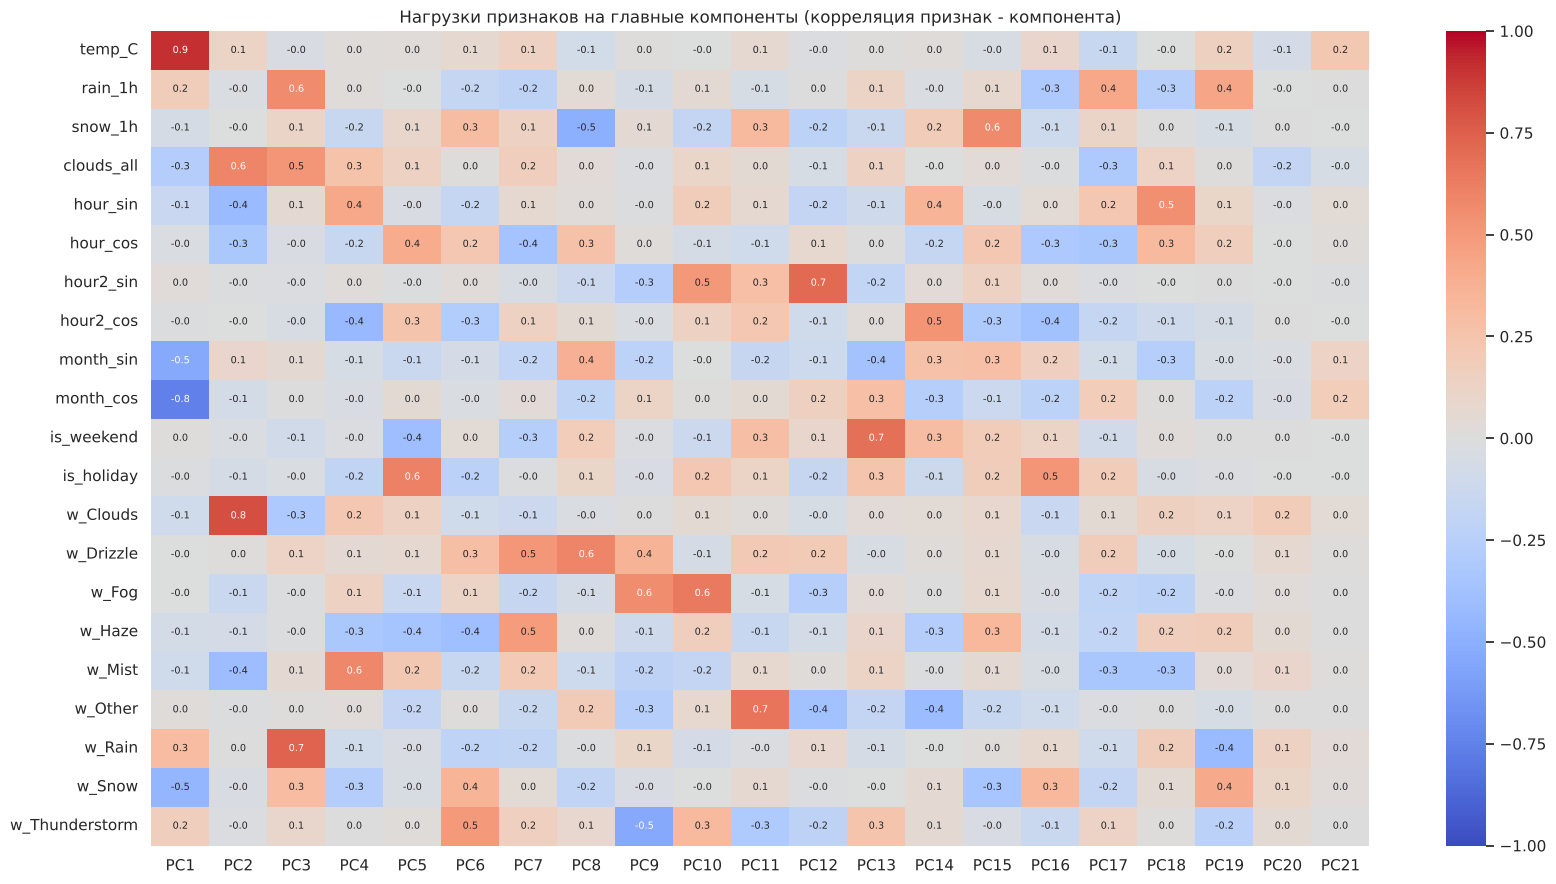

In [ ]:
VAR_THRESHOLD = 0.90
N_COMP = int(np.argmax(cum >= VAR_THRESHOLD) + 1)
N_KAISER = int((pca_full.explained_variance_ > 1).sum())
print(f"По порогу {VAR_THRESHOLD:.0%}: k = {N_COMP} (накопленная доля {cum[N_COMP-1]:.2%})")
print(f"По критерию Кайзера (λ>1): k = {N_KAISER} (накопленная доля {cum[N_KAISER-1]:.2%})")

pca = PCA(n_components=N_COMP, random_state=RANDOM_STATE).fit(X_train_s)
X_train_pc, X_test_pc = pca.transform(X_train_s), pca.transform(X_test_s)
print("Форма train:", X_train.shape, "->", X_train_pc.shape, "| test:", X_test.shape, "->", X_test_pc.shape)

loadings = pd.DataFrame(pca_full.components_.T * np.sqrt(pca_full.explained_variance_),
                        index=FEATURES, columns=pc_names)
plt.figure(figsize=(17, 9))
sns.heatmap(loadings, annot=True, fmt=".1f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Нагрузки признаков на главные компоненты (корреляция признак - компонента)")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Выбираем число компонент двумя стандартными способами: по порогу накопленной дисперсии 90% (`N_COMP`) и по критерию Кайзера (λ > 1, `N_KAISER`). Затем обучаем PCA с `N_COMP` компонентами и преобразуем обучающую и тестовую выборки теми же осями (на тесте — только `transform`). Вычисляем **нагрузки** — корреляции исходных признаков с компонентами (собственные векторы, умноженные на корень из λ) — и показываем их тепловой картой для всех 21 компонент: она показывает, из каких признаков «состоит» каждая компонента.

**Что видно из вывода:** по порогу 90% — k = 17 (91.3%), по Кайзеру — k = 11 (64.3%); размерность обучающей матрицы уменьшилась с 21 до 17 столбцов. Интерпретация нагрузок — в абзаце ниже.

**Выбор числа компонент и нагрузки.** Для основного варианта по заданию выбран порог накопленной дисперсии 90%: минимальное k, при котором накопленная доля ≥ 0.90, — **k = 17** (91.3%). Размер обучающей матрицы изменился с (32 449, 21) на (32 449, 17); тестовая выборка преобразуется теми же осями (`pca.transform`) и имеет форму (8 113, 17). Дополнительно рассмотрены варианты k = 11 (Кайзер), k = 19 (по излому на scree plot и кросс-валидации, см. ниже) и k = 21 (без сокращения).

**Нагрузки** (корреляции исходных признаков с компонентами; красный — положительная связь, синий — отрицательная):

- **PC1** — «сезон и температура»: `temp_C` (+0.9) против `month_cos` (−0.8), `month_sin` (−0.5), `w_Snow` (−0.5);
- **PC2** — «облачность»: `w_Clouds` (+0.8), `clouds_all` (+0.6);
- **PC3** — «дождь»: `w_Rain` (+0.7), `rain_1h` (+0.6), `clouds_all` (+0.5);
- остальные компоненты в основном выделяют отдельные редкие индикаторы (`w_Drizzle`, `w_Fog`, `w_Thunderstorm`, `w_Other`, `is_holiday`, `is_weekend`, `snow_1h`) или отдельные гармоники часа (`hour2_sin` — PC12, `hour2_cos` — PC14, `hour_sin` — PC18).

То есть компоненты, как правило, просто повторяют отдельные исходные признаки — ещё одно подтверждение того, что признаки почти независимы. **Важно:** сигнал о времени суток (`hour_*`) — самый важный для прогноза — «размазан» по многим компонентам, в том числе по PC16–PC19 с небольшой дисперсией.

In [23]:
pc_df = pd.DataFrame(X_train_pc, columns=pc_names[:N_COMP])
off_diag = pc_df.corr().values[~np.eye(N_COMP, dtype=bool)]
print(f"Максимальная |корреляция| между компонентами (train): {np.abs(off_diag).max():.2e}")
vif_pc = compute_vif(pc_df)
print(f"VIF компонент: min = {vif_pc.min():.4f}, max = {vif_pc.max():.4f}")
print(f"VIF исходных признаков: max = {vif_orig.max():.2f}  ({vif_orig.idxmax()})")

Максимальная |корреляция| между компонентами (train): 3.51e-15


VIF компонент: min = 1.0000, max = 1.0000
VIF исходных признаков: max = 4.84  (temp_C)


**Пояснение к блоку кода.** Проверяем, что мультиколлинеарность действительно устранена: считаем максимальную по модулю корреляцию между компонентами и VIF компонент, сравниваем с максимальным VIF исходных признаков.

**Что видно из вывода:** корреляции между компонентами порядка 10⁻¹⁵ (то есть нулевые), VIF = 1.0000 у всех компонент против 4.84 у `temp_C`.

**Проверка устранения мультиколлинеарности.** Корреляции между компонентами равны нулю с точностью до ошибки округления (максимум по модулю ≈ 4·10⁻¹⁵), VIF каждой компоненты равен 1.0000 (против максимального VIF исходных признаков 4.84 у `temp_C`). Мультиколлинеарность в формальном смысле **устранена**: по построению PCA компоненты ортогональны. Но, как показано ниже, избавление от слабой мультиколлинеарности и сокращение размерности — разные вещи, и платой за сокращение до 17 компонент оказывается потеря качества.

## 6. Модели на главных компонентах и сравнение

k по кросс-валидации (допуск 1% от лучшего CV RMSE): 19


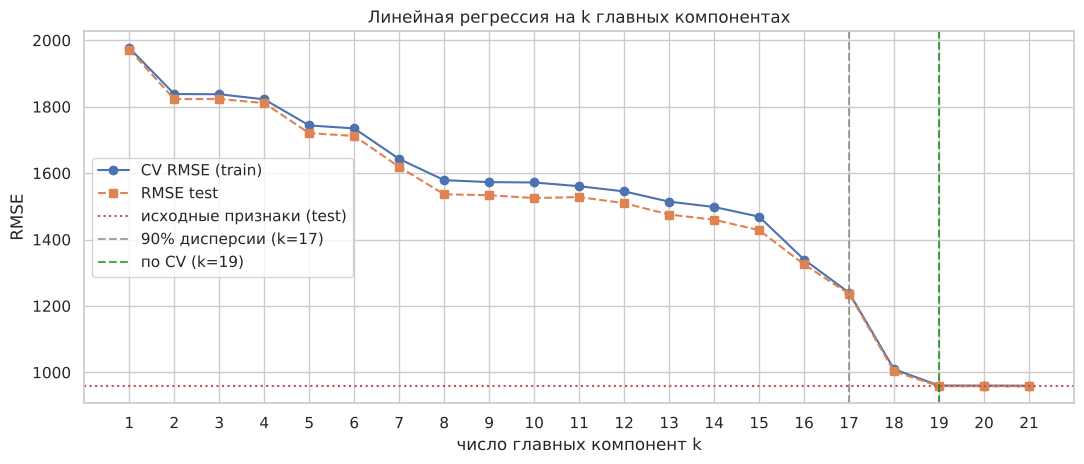

k,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
CV RMSE,"1,976.9994","1,838.1891","1,837.5650","1,822.1728","1,743.5926","1,734.6953","1,642.5722","1,578.8198","1,572.8946","1,571.8077",...,"1,544.9508","1,514.0957","1,498.0472","1,468.8372","1,339.6999","1,239.9064","1,009.4206",960.2962,960.1674,959.8086
RMSE test,"1,972.2535","1,822.8709","1,823.2408","1,810.9953","1,720.2249","1,712.0493","1,618.8003","1,536.1394","1,533.5096","1,524.9993",...,"1,509.4899","1,475.3104","1,459.6141","1,428.2898","1,325.0216","1,236.4005","1,002.8220",958.4159,958.2486,957.8073
R2 test,0.0076,0.1523,0.1519,0.1633,0.2450,0.2522,0.3314,0.3980,0.4000,0.4067,...,0.4187,0.4447,0.4565,0.4795,0.5521,0.6100,0.7434,0.7657,0.7657,0.7659


In [ ]:
pca_steps = lambda k: [("scaler", StandardScaler()), ("pca", PCA(n_components=k, random_state=RANDOM_STATE))]

ks = list(range(1, len(FEATURES) + 1))
rows = []
for k in ks:
    m = Pipeline(pca_steps(k) + [("model", LinearRegression())])
    cv_r = -cross_val_score(m, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
    m.fit(X_train, y_train)
    rows.append({"k": k, "CV RMSE": cv_r, "RMSE test": rmse(y_test, m.predict(X_test)), "R2 test": r2_score(y_test, m.predict(X_test))})
sweep = pd.DataFrame(rows)
K_CV = int(sweep.loc[sweep["CV RMSE"] <= sweep["CV RMSE"].min() * 1.01, "k"].min())
print(f"k по кросс-валидации (допуск 1% от лучшего CV RMSE): {K_CV}")

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(sweep["k"], sweep["CV RMSE"], "o-", color="#4C72B0", label="CV RMSE (train)")
ax.plot(sweep["k"], sweep["RMSE test"], "s--", color="#DD8452", label="RMSE test")
ax.axhline(res_orig.set_index("Модель").loc["Линейная", "RMSE test"], color="r", ls=":", label="исходные признаки (test)")
for k_, c_, lab in [(N_COMP, "gray", f"90% дисперсии (k={N_COMP})"), (K_CV, "green", f"по CV (k={K_CV})")]:
    ax.axvline(k_, color=c_, ls="--", alpha=.7, label=lab)
ax.set_xlabel("число главных компонент k"); ax.set_ylabel("RMSE"); ax.set_xticks(ks)
ax.set_title("Линейная регрессия на k главных компонентах"); ax.legend()
plt.tight_layout(); plt.show()
sweep.set_index("k").T

**Пояснение к блоку кода.** Чтобы выбрать число компонент по качеству прогноза, а не только по дисперсии, для каждого k от 1 до 21 обучается конвейер `StandardScaler → PCA(k) → LinearRegression`; считается CV-RMSE на обучающей выборке (по нему выбирается `K_CV`: наименьшее k, при котором ошибка не хуже лучшей более чем на 1%) и, для иллюстрации, RMSE на тесте. Результат — график зависимости ошибки от k и таблица значений.

**Вывод по графику.** Обе кривые (CV и тест) идут вместе и почти совпадают — значит, выбор k по CV честен. Ошибка убывает медленно до k ≈ 16 и резко падает при k = 17–19, после чего выходит на «полку» на уровне моделей на исходных признаках (красная пунктирная линия). Вертикальные линии показывают: порог 90% (k = 17) лежит на склоне, где ошибка ещё велика, а выбор по CV (k = 19) — уже на полке. Интерпретация — в абзаце ниже.

**Выбор k по кросс-валидации.** Чтобы выбрать число компонент не только по доле дисперсии, линейная регрессия обучена на k = 1…21 первых главных компонентах; для каждого k посчитан CV RMSE на обучающей выборке (тест для выбора не использовался) и, для иллюстрации, RMSE на тесте.

Ключевое наблюдение — **качество регрессии растёт не плавно вместе с объяснённой дисперсией, а скачком в конце**: при k = 16 тестовый RMSE ≈ 1 325, при k = 17 — 1 236, при k = 18 — 1 003, при k = 19 — **958.4**, что совпадает с RMSE на исходных признаках (957.8). Компоненты PC20 и PC21 (почти нулевая дисперсия, остаточная коллинеарность) для прогноза не нужны: их вклад в линейную модель ничтожен (≈ 20–30 автомобилей на одно стандартное отклонение компоненты): k = 19 даёт то же качество, что и все 21.

Причина: **PCA не учитывает целевую переменную** (это метод без учителя). Он упорядочивает компоненты по дисперсии признаков, а не по связи с `traffic_volume`. Самый информативный признак — время суток (`hour_cos` r = −0.77) — не доминирует по дисперсии (после стандартизации все признаки имеют дисперсию 1) и «размазан» по компонентам (в том числе PC16–PC19); для прогноза особенно важна PC18 — её вклад в линейную модель (≈ 730 автомобилей на одно стандартное отклонение) сравним с PC2 и почти в четыре раза больше, чем у PC1 (≈ 190), хотя дисперсия PC18 ниже; отбросив их ради порога 90%, мы выбрасываем информацию о времени суток. Правило «достаточно 90% дисперсии» для регрессии здесь неприменимо.

Наименьшее k, при котором CV RMSE не хуже лучшего более чем на 1%: **k = 19** (CV RMSE 960.3 против 959.8 при k = 21).

In [25]:
variants = {f"PCA, k={N_COMP} (90% дисп.)": N_COMP, f"PCA, k={N_KAISER} (Кайзер)": N_KAISER,
            f"PCA, k={K_CV} (по CV)": K_CV, f"PCA, k={len(FEATURES)} (все)": len(FEATURES)}
res_list = [res_orig]
for label, k in variants.items():
    r, _ = fit_and_score(make_models(pca_steps(k)), X_train, y_train, X_test, y_test, label)
    res_list.append(r)

results = pd.concat(res_list, ignore_index=True)
cols = ["Признаки", "Модель", "alpha", "CV RMSE", "RMSE train", "RMSE test", "R2 train", "R2 test", "MAPE test, %"]
results[cols]

,Признаки,Модель,alpha,CV RMSE,RMSE train,RMSE test,R2 train,R2 test,"MAPE test, %"
0,Исходные,Линейная,NaN,959.8086,959.0546,957.8073,0.7667,0.7659,138.6339
1,Исходные,Лассо,1.2690,959.7747,959.0814,957.7935,0.7667,0.7660,138.9022
2,Исходные,Гребневая,13.7382,959.8079,959.0548,957.8043,0.7667,0.7659,138.6858
3,"PCA, k=17 (90% дисп.)",Линейная,NaN,"1,239.9064","1,239.5893","1,236.4005",0.6103,0.6100,189.0931
4,"PCA, k=17 (90% дисп.)",Лассо,0.8532,"1,239.9017","1,239.5939","1,236.3433",0.6103,0.6100,189.3215
5,"PCA, k=17 (90% дисп.)",Гребневая,35.6225,"1,239.9048","1,239.5903","1,236.3729",0.6103,0.6100,189.2062
6,"PCA, k=11 (Кайзер)",Линейная,NaN,"1,560.5449","1,551.9458","1,527.8684",0.3891,0.4044,261.0087
7,"PCA, k=11 (Кайзер)",Лассо,0.0010,"1,560.5449","1,551.9458","1,527.8683",0.3891,0.4044,261.0089
8,"PCA, k=11 (Кайзер)",Гребневая,385.6620,"1,560.4574","1,551.9948","1,528.2421",0.3891,0.4041,261.7620
9,"PCA, k=19 (по CV)",Линейная,NaN,960.2962,959.6035,958.4159,0.7665,0.7657,138.9660


**Пояснение к блоку кода.** Обучаем те же три модели (линейная, лассо, гребневая) с тем же подбором `alpha` и теми же разбиениями кросс-валидации, но на главных компонентах: внутри `Pipeline` стоят `StandardScaler → PCA(k) → модель`, поэтому PCA заново обучается в каждом блоке кросс-валидации. Рассматриваются четыре значения k: по порогу 90% (17), по Кайзеру (11), по CV (19) и все 21 (контроль). Результаты склеиваются с таблицей для исходных признаков в общую таблицу `results`.

**Что видно из таблицы:** на k = 19 и k = 21 метрики совпадают с исходными (RMSE ≈ 958, R² ≈ 0.766), на k = 17 хуже (RMSE ≈ 1 236, R² ≈ 0.61), на k = 11 — значительно хуже (RMSE ≈ 1 528, R² ≈ 0.40). Разбор — в абзаце после диаграммы.

**Модели на главных компонентах.** Те же три модели, та же сетка `alpha`, те же разбиения кросс-валидации (`KFold`, `random_state=42`) и тот же тест (те же 8 113 наблюдений) — условия сравнения одинаковы. Внутри `Pipeline` (`StandardScaler → PCA → модель`) PCA заново обучается на каждом блоке кросс-валидации. Рассмотрены четыре варианта: k = 17 (по порогу 90%, основной по заданию), k = 11 (критерий Кайзера), k = 19 (по CV и излому scree plot) и k = 21 (без сокращения — контроль).

In [26]:
base = results[results["Признаки"] == "Исходные"].set_index("Модель")
diff = results[results["Признаки"] != "Исходные"].copy()
for c in ["CV RMSE", "RMSE test", "R2 test", "MAPE test, %"]:
    diff[f"Δ {c}"] = diff.apply(lambda r: r[c] - base.loc[r["Модель"], c], axis=1)
diff[["Признаки", "Модель", "Δ CV RMSE", "Δ RMSE test", "Δ R2 test", "Δ MAPE test, %"]]

,Признаки,Модель,Δ CV RMSE,Δ RMSE test,Δ R2 test,"Δ MAPE test, %"
3,"PCA, k=17 (90% дисп.)",Линейная,280.0978,278.5932,-0.1560,50.4592
4,"PCA, k=17 (90% дисп.)",Лассо,280.1270,278.5497,-0.1559,50.4193
5,"PCA, k=17 (90% дисп.)",Гребневая,280.0969,278.5686,-0.1559,50.5204
6,"PCA, k=11 (Кайзер)",Линейная,600.7363,570.0610,-0.3615,122.3748
7,"PCA, k=11 (Кайзер)",Лассо,600.7702,570.0748,-0.3615,122.1067
8,"PCA, k=11 (Кайзер)",Гребневая,600.6495,570.4378,-0.3618,123.0763
9,"PCA, k=19 (по CV)",Линейная,0.4876,0.6086,-0.0003,0.3321
10,"PCA, k=19 (по CV)",Лассо,0.5167,0.6034,-0.0003,0.2430
11,"PCA, k=19 (по CV)",Гребневая,0.4879,0.6083,-0.0003,0.3308
12,"PCA, k=21 (все)",Линейная,0.0000,0.0000,-0.0000,0.0000


**Пояснение к блоку кода.** Для каждой модели на главных компонентах вычисляется разность метрик с моделью того же типа на исходных признаках: положительное Δ RMSE и Δ MAPE означает ухудшение, отрицательное Δ R² — тоже ухудшение. Это упрощает прямое сравнение «до и после PCA».

**Что видно из таблицы:** для k = 17 Δ RMSE ≈ +279, Δ R² ≈ −0.156, Δ MAPE ≈ +50 п.п.; для k = 11 Δ RMSE ≈ +570, Δ R² ≈ −0.36; для k = 19 разности близки к нулю (Δ RMSE ≈ +0.6, Δ R² ≈ −0.0003); для k = 21 — ровно нули.

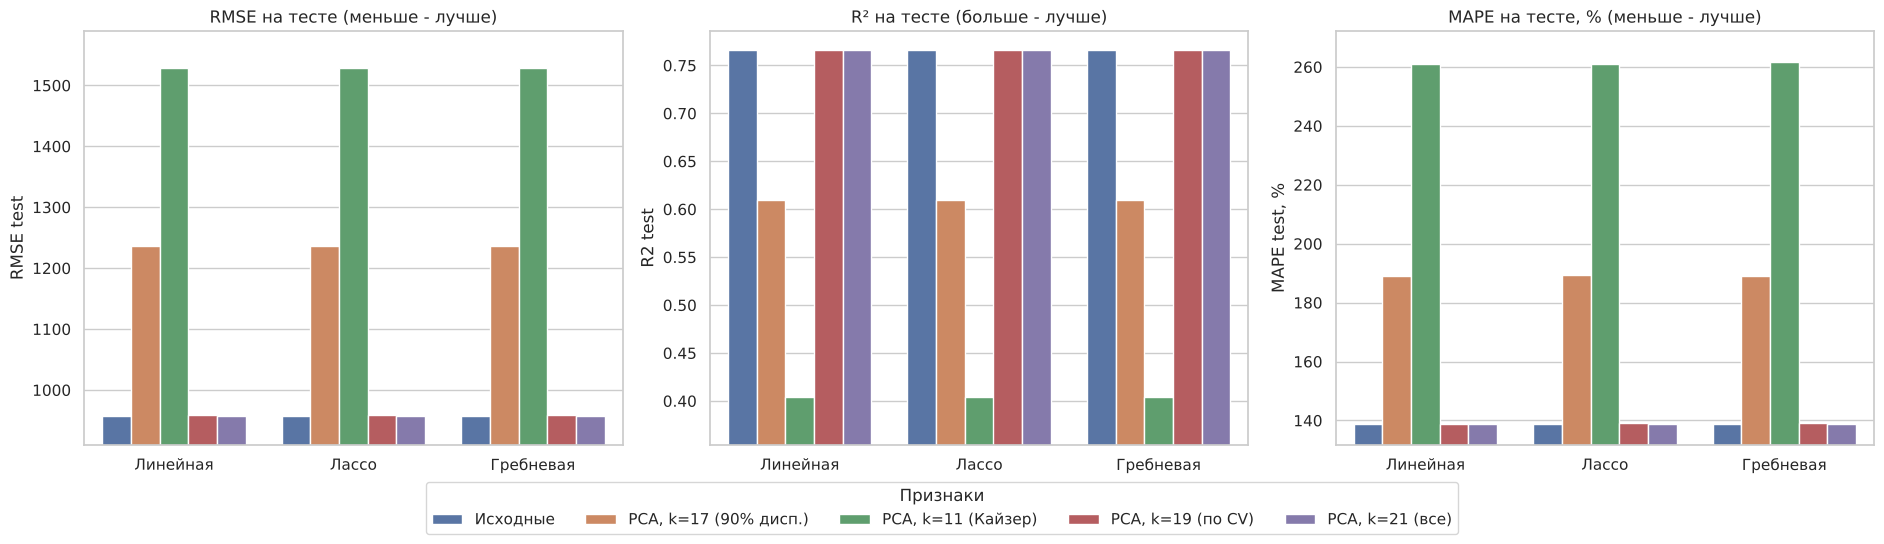

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
order = list(results["Признаки"].unique())
for ax, (col, title) in zip(axes, [("RMSE test", "RMSE на тесте (меньше - лучше)"),
                                   ("R2 test", "R² на тесте (больше - лучше)"),
                                   ("MAPE test, %", "MAPE на тесте, % (меньше - лучше)")]):
    sns.barplot(data=results, x="Модель", y=col, hue="Признаки", hue_order=order, ax=ax, palette="deep")
    ax.set_title(title); ax.set_xlabel("")
    if col == "R2 test": ax.set_ylim(results[col].min() - 0.05, results[col].max() + 0.02)
    if col == "RMSE test": ax.set_ylim(results[col].min() * 0.95, results[col].max() * 1.04)
    if col == "MAPE test, %": ax.set_ylim(results[col].min() * 0.95, results[col].max() * 1.04)
    handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), title="Признаки", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Столбчатые диаграммы сравнивают три метрики на тесте (RMSE, R², MAPE) для всех моделей и вариантов признаков; цвет — вариант признаков, группа столбцов — тип модели. Оси начинаются не с нуля, чтобы были видны различия между близкими вариантами; легенда вынесена под графики.

**Вывод по диаграммам.** Внутри каждого варианта признаков три модели дают почти одинаковые столбцы — регуляризация ничего не меняет. Между вариантами разница огромна: исходные признаки, PCA с k = 19 и k = 21 (синий, красный, фиолетовый) практически равны; k = 17 (оранжевый) заметно хуже; k = 11 (зелёный) хуже всех — выше всех по RMSE и MAPE и ниже всех по R². Таблицу и разбор см. ниже.

**Итоговая таблица метрик (тест) и разность «PCA минус исходные признаки».**

| Признаки | RMSE (тест) | R² (тест) | MAPE | Что произошло |
|---|---|---|---|---|
| Исходные (21) | 957.8 | 0.766 | 138.6% | база |
| **PCA, k = 17 (90% дисперсии)** | **1 236.4** | **0.610** | **189.1%** | ухудшение по всем метрикам: RMSE +279, R² −0.156, MAPE +50 п.п. |
| PCA, k = 11 (Кайзер) | 1 527.9 | 0.404 | 261.0% | сильное ухудшение: R² −0.36 |
| **PCA, k = 19 (по CV)** | **958.4** | **0.766** | 139.0% | практически без изменений: RMSE +0.6, R² −0.0003 |
| PCA, k = 21 (все) | 957.8 | 0.766 | 138.6% | идентично исходным (просто поворот осей) |

Вывод по каждому пункту:

- **k = 21.** Линейная и гребневая регрессии на всех компонентах дают в точности те же метрики, что и на исходных признаках: PCA — это поворот осей, а линейная модель с таким поворотом не меняется. У лассо отличия в 3–4 знаке: L1-штраф неинвариантен к повороту.
- **k = 19.** После удаления двух компонент с нулевой дисперсией (остаточная коллинеарность) качество не меняется (ухудшение RMSE на 0.6 автомобиля — шум), зато признаков на 2 меньше и мультиколлинеарность полностью устранена. **Это лучший вариант использования PCA на этих данных.**
- **k = 17 (по порогу 90%)** и **k = 11 (Кайзер):** критерии, основанные на дисперсии, **резко ухудшают** прогноз — R² падает с 0.77 до 0.61 и 0.40.
- Лассо и гребневая регрессия, как и на исходных признаках, дают такие же результаты, что и линейная: регуляризация при 32 тысячах наблюдений и слабой коллинеарности ничего не улучшает.

**Итог сравнения:** PCA **не улучшил** качество (исходные признаки уже почти не коллинеарны), а при выборе k по доле дисперсии даже ухудшил. Сохранить качество при устранении мультиколлинеарности удаётся только при k = 19.

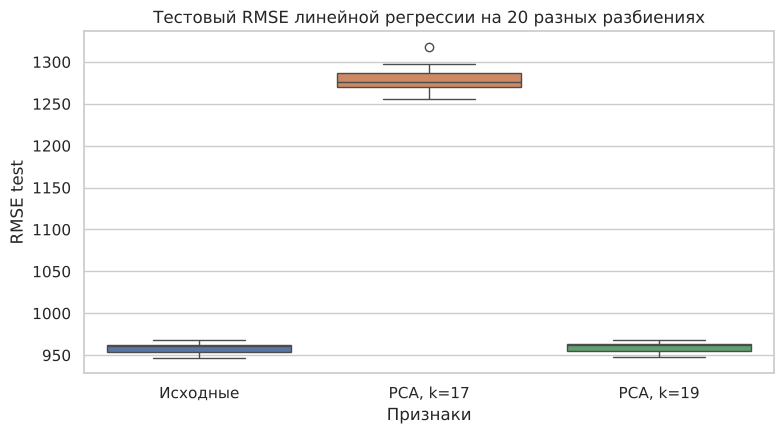

,mean,std
Признаки,,
"PCA, k=17","1,279.6056",15.1850
"PCA, k=19",959.0345,6.3246
Исходные,958.6631,6.3302


In [28]:
rows = []
for seed in range(20):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    for label, steps in [("Исходные", [("scaler", StandardScaler())]), (f"PCA, k={N_COMP}", pca_steps(N_COMP)),
                         (f"PCA, k={K_CV}", pca_steps(K_CV))]:
        m = Pipeline(steps + [("model", LinearRegression())]).fit(Xtr, ytr)
        rows.append({"seed": seed, "Признаки": label, "RMSE test": rmse(yte, m.predict(Xte))})
rob = pd.DataFrame(rows)
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=rob, x="Признаки", y="RMSE test", palette="deep")
plt.title("Тестовый RMSE линейной регрессии на 20 разных разбиениях")
plt.tight_layout(); plt.show()
rob.groupby("Признаки")["RMSE test"].agg(["mean", "std"])

**Пояснение к блоку кода.** Чтобы убедиться, что выводы не зависят от удачного разбиения `random_state=42`, линейная регрессия обучается и оценивается на 20 разных случайных разбиениях для трёх вариантов признаков: исходные, PCA(k = 17) и PCA(k = 19). Строится диаграмма размаха тестового RMSE по разбиениям и выводятся среднее и стандартное отклонение.

**Вывод по графику и таблице** — в абзаце ниже: «ящики» исходных признаков и k = 19 перекрываются, k = 17 лежит значительно выше.

**Устойчивость выводов к разбиению.** На графике — тестовый RMSE линейной регрессии на 20 различных `random_state` для трёх вариантов: исходные признаки, PCA(19) и PCA(17). Средний RMSE (± стандартное отклонение по разбиениям): **958.7 ± 6.3** на исходных признаках, **959.0 ± 6.3** при k = 19 и **1 279.6 ± 15.2** при k = 17. Разница между исходными признаками и k = 19 (0.4) более чем в 15 раз меньше разброса между разбиениями — то есть статистически неотличима; ухудшение при k = 17 (+321) в десятки раз больше разброса и воспроизводится на всех 20 разбиениях (на каждом k = 17 хуже исходных признаков более чем на 100). Вывод устойчив и не зависит от удачного выбора `random_state=42`.

## 7. Анализ погрешности и пути повышения точности

In [29]:
# Эксперимент 1: хронологическое разбиение (первые 80% по времени - обучение, последние 20% - тест)
cut = int(len(df) * 0.8)
Xtr_t, Xte_t, ytr_t, yte_t = X.iloc[:cut], X.iloc[cut:], y.iloc[:cut], y.iloc[cut:]
m_t = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]).fit(Xtr_t, ytr_t)
print(f"Хронологическое разбиение: RMSE = {rmse(yte_t, m_t.predict(Xte_t)):.1f}, "
      f"R2 = {r2_score(yte_t, m_t.predict(Xte_t)):.3f}, MAPE = {mape(yte_t, m_t.predict(Xte_t)):.1f}%")

print(f"Доля наблюдений с трафиком < 500: случайный тест {(y_test < 500).mean():.1%}, хронологический тест {(yte_t < 500).mean():.1%}")
print(f"Минимальный трафик: случайный тест {y_test.min()}, хронологический тест {yte_t.min()}")
print(f"Период хронологического теста: {df.loc[cut, 'date_time'].date()} - {df['date_time'].iloc[-1].date()}")

# Эксперимент 2: взаимодействие "выходной x время суток" (в выходные суточный профиль другой)
X_int = X.copy()
for c in ["hour_sin", "hour_cos", "hour2_sin", "hour2_cos"]:
    X_int[f"wkend_x_{c}"] = X["is_weekend"] * X[c]
Xtr_i, Xte_i, ytr_i, yte_i = train_test_split(X_int, y, test_size=0.2, random_state=RANDOM_STATE)
m_i = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]).fit(Xtr_i, ytr_i)

# Эксперимент 3: то же + One-Hot час суток вместо синусов/косинусов
X_h = pd.concat([X_int.drop(columns=["hour_sin", "hour_cos", "hour2_sin", "hour2_cos"]),
                 pd.get_dummies(hour, prefix="h").astype(int).drop(columns="h_0")], axis=1)
Xtr_h, Xte_h, ytr_h, yte_h = train_test_split(X_h, y, test_size=0.2, random_state=RANDOM_STATE)
m_h = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]).fit(Xtr_h, ytr_h)

def row(name, model, Xte_, yte_):
    p = model.predict(Xte_); big = yte_ >= 100
    return {"Вариант": name, "RMSE test": rmse(yte_, p), "R2 test": r2_score(yte_, p),
            "MAPE test, %": mape(yte_, p), "MAPE (трафик >= 100), %": mape(yte_[big], p[big])}

improve = pd.DataFrame([
    row("Базовая гребневая (исходные признаки)", fitted_orig["Гребневая"], X_test, y_test),
    row("+ взаимодействие выходной x час", m_i, Xte_i, yte_i),
    row("+ One-Hot час суток", m_h, Xte_h, yte_h),
])
improve

Хронологическое разбиение: RMSE = 948.9, R2 = 0.768, MAPE = 46.5%
Доля наблюдений с трафиком < 500: случайный тест 11.1%, хронологический тест 11.7%
Минимальный трафик: случайный тест 1, хронологический тест 151
Период хронологического теста: 2017-10-26 - 2018-09-30


,Вариант,RMSE test,R2 test,"MAPE test, %","MAPE (трафик >= 100), %"
0,Базовая гребневая (исходные признаки),957.8043,0.7659,138.6858,46.5697
1,+ взаимодействие выходной x час,788.5887,0.8413,134.9095,33.9703
2,+ One-Hot час суток,613.7116,0.9039,134.1217,25.3791


**Пояснение к блоку кода.** Блок проверяет, как повысить точность и насколько выводы зависят от способа разбиения. (1) **Хронологическое разбиение:** обучение на первых 80% времени, тест на последних 20% — проверка на «будущем»; дополнительно печатаются доля малых значений трафика и минимум трафика в тесте. (2) **Взаимодействие «выходной × час»:** добавляются произведения `is_weekend` на гармоники часа, чтобы в выходные был свой суточный профиль; модель — гребневая регрессия со стандартизацией. (3) **One-Hot час суток** вместо `sin/cos` (плюс то же взаимодействие) — позволяет модели задать свою «высоту» каждому часу. Для вариантов (2) и (3) сравниваются RMSE, R², MAPE и MAPE по наблюдениям с трафиком ≥ 100.

**Что видно из вывода:** хронологический тест: RMSE 948.9, R² 0.768 (то же качество, MAPE 46.5% из-за отсутствия сверхмалых значений: минимум 151); вариант (2): RMSE 788.6, R² 0.841; вариант (3): RMSE 613.7, R² 0.904. Подробный анализ — ниже.

**Анализ причин ошибки и способы её снизить.** Итоговая метрика линейных моделей — RMSE ≈ 958 автомобилей в час при среднем трафике 3 260 и стандартном отклонении 1 987 (R² = 0.77). Причины ошибки:

1. **Нелинейный суточный профиль.** Основная причина — две гармоники `sin/cos` не воспроизводят резкий рост в 5–7 ч и спад вечером (график среднего остатка по часам). Это смещение модели.
2. **Различие суточных профилей в будни и выходные.** Одна и та же кривая часа для всех дней недели некорректна: в субботу и воскресенье пика нет.
3. **Слабая информативность погоды.** Температура, осадки и облачность почти не влияют на трафик (|r| < 0.15), поэтому «шум» объяснить нечем.
4. **Неучтённые факторы** (аварии, дорожные работы, дни перед праздниками, события в городе) в данных отсутствуют.
5. **Отрицательные прогнозы** линейной модели при малом трафике.

**Проведённые эксперименты (код выше):**

- **Хронологическое разбиение** (обучение на первых 80% по времени, тест — с 26.10.2017 по 30.09.2018): RMSE = 948.9, R² = 0.768 — практически то же качество, что при случайном разбиении (957.8 и 0.766). Вывод о качестве не зависит от способа разбиения. MAPE при этом меньше (46.5%), потому что в этом тестовом периоде нет сверхмалых значений трафика (минимум 151 против 1 в случайном тесте) — ещё одно подтверждение того, что MAPE определяется единичными выбросами.
- **Взаимодействие «выходной × час»** (признаки `is_weekend × hour_*`): RMSE 957.8 → **788.6**, R² 0.766 → **0.841**.
- **Взаимодействие + One-Hot кодирование часа суток** (вместо `sin/cos`): RMSE → **613.7**, R² → **0.904**. MAPE по наблюдениям с трафиком ≥ 100 падает с 46.6% до **25.4%**. Общий MAPE остаётся ≈ 134% — его по-прежнему определяют 13 наблюдений с трафиком < 100.

Таким образом, **модель остаётся линейной, но точность растёт благодаря более удачным признакам** (инженерия признаков), а не усложнению модели. Другие возможные улучшения: нелинейные модели (деревья, градиентный бустинг — ожидаемо точнее, поскольку зависимость от часа и дня недели табличная), лаговые признаки (трафик предыдущего часа), логарифмирование цели, обрезание отрицательных прогнозов.

## Заключение

1. **Данные.** Датасет Metro Interstate Traffic Volume: 48 204 почасовые записи за 2012–2018 годы. После очистки (удаление 17 полных дубликатов, 7 612 повторов на один час и 13 аномальных строк — температура 0 К, дождь 9 831 мм, нулевой трафик) осталось 40 562 наблюдения. Пропусков нет (значение `None` в `holiday` означает «не праздник»). Целевая переменная имеет бимодальное распределение, определяемое временем суток.
2. **Признаки.** Сформировано 21 признак: погода, циклическое кодирование часа и месяца, выходной, праздник и One-Hot тип погоды.
3. **Связь с целью.** Трафик определяется в первую очередь временем суток (`hour_cos`, r = −0.77) и выходными (r = −0.21); погода (температура, осадки, облачность) связана с ним слабо (|r| < 0.15).
4. **Мультиколлинеарность.** Слабая: максимальный VIF 4.84 у `temp_C` (из-за связи с месяцем, r = −0.71 с `month_cos`); порог 5 не превышен.
5. **Модели на исходных признаках.** Линейная, лассо- и гребневая регрессии практически идентичны: RMSE ≈ 957.8 автомобилей в час, R² ≈ 0.766, MAPE ≈ 139%. Переобучения нет (RMSE train 959.1 и test 957.8), регуляризация не нужна. Ограничение — в линейной форме зависимости от часа суток (недообучение), что видно по остаткам.
6. **MAPE.** Значение 139% вызвано 13 наблюдениями с трафиком < 100 (минимум — 1 автомобиль); медианная процентная ошибка — 19%, а MAPE без этих наблюдений — 46.6%. На данных с близкими к нулю значениями MAPE ненадёжна, основными метриками следует считать RMSE и R².
7. **PCA.** После стандартизации PCA устраняет мультиколлинеарность (VIF компонент = 1), но дисперсия распределена почти равномерно (PC1 — всего 10.4%), поэтому сжать данные без потерь нельзя. На графике каменистой осыпи единственный излом — между 19-й и 20-й компонентами (λ: 0.78 → 0.12).
8. **Сравнение моделей.** Критерии, основанные на дисперсии, **ухудшают** регрессию: k = 17 (порог 90%) — R² 0.61 (RMSE +279), k = 11 (Кайзер) — R² 0.40. Причина: PCA не учитывает цель и отбрасывает малодисперсные компоненты, содержащие информацию о времени суток. Выбор k = 19 (по излому и кросс-валидации) сохраняет качество (RMSE 958.4, R² 0.766) при устранении мультиколлинеарности — это оптимальный вариант. На всех 21 компонентах результат совпадает с исходным. Результат устойчив на 20 разных разбиениях.
9. **Повышение точности.** Учёт взаимодействия «выходной × час» и One-Hot кодирование часа поднимают R² до 0.84 и 0.90 (RMSE 788.6 и 613.7) без смены класса модели. Хронологическое разбиение даёт то же качество, что случайное (RMSE 948.9).

**Практический вывод:** для этих данных главная задача — не борьба с мультиколлинеарностью (она слабая), а правильное описание суточного и недельного ритма трафика; PCA следует применять с выбором числа компонент по качеству прогноза, а не только по доле объяснённой дисперсии.

## Список источников

1. Hogue J. *Metro Interstate Traffic Volume* [Электронный ресурс] // UCI Machine Learning Repository. — https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume (дата обращения: 27.10.2026). Копия набора также доступна на Kaggle.
2. Pedregosa F. et al. *Scikit-learn: Machine Learning in Python* // Journal of Machine Learning Research. — 2011. — Vol. 12. — P. 2825–2830. Документация: https://scikit-learn.org/stable/ (разделы «Linear Models», «Decomposing signals in components (PCA)», «Cross-validation»).
3. McKinney W. *Data Structures for Statistical Computing in Python* // Proceedings of the 9th Python in Science Conference. — 2010. — P. 56–61. Документация pandas: https://pandas.pydata.org/docs/.
4. Hastie T., Tibshirani R., Friedman J. *The Elements of Statistical Learning: Data Mining, Inference, and Prediction*. — 2nd ed. — Springer, 2009 (гл. 3 «Linear Methods for Regression», регуляризация Ridge и Lasso; разд. 14.5 «Principal Components»).
5. James G., Witten D., Hastie T., Tibshirani R. *An Introduction to Statistical Learning*. — Springer, 2013 (гл. 3, 6).
6. Jolliffe I. T. *Principal Component Analysis*. — 2nd ed. — Springer, 2002.
7. Лекционные материалы курса «Машинное и глубокое обучение»: «Машинное обучение, регрессия и факторный анализ», «Регрессия», «Факторный анализ» (презентации и конспекты из комплекта к лабораторной работе).
8. Документация Matplotlib (https://matplotlib.org/) и Seaborn (https://seaborn.pydata.org/).